# Existence of the C-type renormalisation two-cycle

> We present the computer-assisted portion of a proof of existence for the C-type renormalisation two-cycle, for maps of the plane.

## Setting

### Renormalisation operator

For pairs of functions $g,f:\mathbb{R}^2\to\mathbb{R}$, we are concerned with the renormalisation operator $R$ defined by

\begin{align}
R(g, f)(x, y)
&= \left(\begin{array}{r}
a^{-1}g(g(ax, by), f(ax, by))\\
b^{-1}f(g(ax, by), f(ax, by))
\end{array}\right),
\end{align}

where $a:=g(g(0,0),f(0,0))$ and $b:=f(g(0,0),f(0,0))$ which enforces the normalisation $R(g,f)(0,0)=(1,1)$.

### Two-cycle

We are interested in a two-cycle of the operator; we would like to find pairs $(g_1,f_1)$ and $(g_2,f_2)$, defined on domains $\Omega_1,\Omega_2\subset\mathbb{C}^2$ (respectively), such that

\begin{align}
R(g_1,f_1) &= (g_2,f_2),\\
R(g_2,f_2) &= (g_1,f_1).
\end{align}

Equivalently, we would like to solve the functional equations

\begin{align}
a_1^{-1}g_1(g_1(a_1x,b_1y),f_1(a_1x,b_1y))
&= g_2(x,y)\quad\mbox{on $\Omega_2$,}\\
b_1^{-1}f_1(g_1(a_1x,b_1y),f_1(a_1x,b_1y))
&= f_2(x,y)\quad\mbox{on $\Omega_2$,}\\
a_2^{-1}g_2(g_2(a_2x,b_2y),f_2(a_2x,b_2y))
&= g_1(x,y)\quad\mbox{on $\Omega_1$,}\\
b_2^{-1}f_2(g_2(a_2x,b_2y),f_2(a_2x,b_2y))
&= f_1(x,y)\quad\mbox{on $\Omega_1$,}\\
\end{align}

where $a_k:=g_k(g_k(0,0),f_k(0,0))$ and $b_k:=f_k(g_k(0,0),f_k(0,0))$ which enforces the normalisation $R(g_k,f_k)(0,0)=(1,1)$.

## Preliminaries

### Multiprocessing

We will distribute certain computations across multiple processors. We will later use directed rounding modes to ensure that rigorous bounds are maintained during floating point operations. We don't assume that these rounding modes are thread-safe and therefore use multiprocessing.

In [1]:
println(VERSION) # Works with Julia 1.10.1

1.10.1


In [2]:
using Distributed

In [3]:
rmprocs(collect(2:maximum(procs()))) # cleanup

Task (done) @0x000076fe97d179e0

In [4]:
addprocs(12)

12-element Vector{Int64}:
  2
  3
  4
  5
  6
  7
  8
  9
 10
 11
 12
 13

### Truncation degree and floating-point type

We will work in a Banach algebra of functions analytic on bidiscs in $\mathbb{C}^2$. In particular, we will bound functions by truncating their power series, to homogeneous degree $N$, to give a polynomial part (for which we will bound the individual coefficients) and a high-order part (for which we will bound a suitable norm).

We will represent upper and lower bounds on real quantities by floating point machine numbers and will carefully control directed-rounding modes during arithmetic operations.

In [5]:
@everywhere begin
    
    # Select the truncation degree N:
    const N::Int64 = 24
    
    # Choose the datatype for Representable Reals (RR):
    const RR = Float64
    const use_crude_rounding = true

    # Choose whether to load precomputed objects:
    const use_precomputed = true

    # Choose whether to create diagrams:
    const draw_figures = true
    
    # These proofs have utilised various floating-point types.
    # Some old code is included below.
    #using MultiFloats; #const RR = Float64x4 # OK for approximate high prec work.
    #using DecFP; const RR = Dec64 #Dec32, Dec128 # Supports rounding.
    #const RR = BigFloat; setprecision(BigFloat, 64*4) # Supports rounding.
end

In [6]:
@everywhere prefix = "dat/C_$(N)_tri_$(RR)_$((RR == BigFloat) ? "$(precision(BigFloat))_" : "")2_"
println("File name prefix: ", prefix)

File name prefix: dat/C_24_tri_Float64_2_


In [7]:
@everywhere begin
    include("rigorous/Preliminaries.jl")  # Preliminary definitions
    include("rigorous/Poly2.jl")          # Polynomials in two variables (numerical/nonrigorous)
    include("rigorous/Poly2D.jl")         # Polynomials expanded with respect to polydisc domain
    include("rigorous/Newton.jl");        # Generic Newton method
end

### Basis size for polynomial approximations

We will begin by finding an approximate two-cycle using operations on polynomials, truncated to homogeneous degree $N$. Thus each analytic function will be approximated by a polynomial

\begin{align}
g(x, y) = \sum_{0\le j+k\le N}a_{jk}x^jy^k.
\end{align}

We denote the number of coefficients for a single map by $N_1$, for a pair of maps by $N_2$, and for two pairs of maps by $N_4$. We note that when approximating the Frechet derivative of a renormalisation operator acting on a pair of polynomial approximations, by a finite-dimensional linear operator, the basis size for the derivative is given by $N_2^2$, for example.

In [8]:
println("Basis sizes:")
println("\$N = ", N, "\$ (truncation degree for homogeneous polynomials in two variables)")
println("\$N_1 = ", tri_basis_size_1, "\$ (basis size for a single polynomial)")
println("\$N_2 = ", tri_basis_size_2, "\$ (basis size for a pair of polynomials)")
println("\$N_4 = ", tri_basis_size_4, "\$ (basis size for a pair of a pair of polynomials)")
println("\$N_4+4 = ", tri_basis_size_4+4, "\$ (basis size for contractivity bounds)")
println("\$N_2^2 = ", tri_basis_size_2^2, "\$ (number of matrix elements for pair derivative)")
println("\$N_4^2 = ", tri_basis_size_4^2, "\$ (number of matrix elements for full derivative)")

Basis sizes:
$N = 24$ (truncation degree for homogeneous polynomials in two variables)
$N_1 = 325$ (basis size for a single polynomial)
$N_2 = 650$ (basis size for a pair of polynomials)
$N_4 = 1300$ (basis size for a pair of a pair of polynomials)
$N_4+4 = 1304$ (basis size for contractivity bounds)
$N_2^2 = 422500$ (number of matrix elements for pair derivative)
$N_4^2 = 1690000$ (number of matrix elements for full derivative)


## Equivalent Operator (C-type) and Frechet derivative

### Equivalent operator

The pairs $(g, f)$ forming the two-cycle of so-called C-type correspond to maps with critical points at the origin of the form $(x,y)\mapsto(x^2,y)$.

We therefore make the ansatz $g(x,y)=G(x^2,y)=:G(X,Y)$, $f(x,y)=F(x^2,y)=:F(X,Y)$, where $X=x^2$ and $Y:=y$, which induces an equivalent operator $T$ given by

$$
T(G, F)(X, Y) = \left(\begin{array}{l}
a^{-1}G(G(a^2X,bY)^2,F(a^2X,bY))\\
b^{-1}F(G(a^2X,bY)^2,F(a^2X,bY))\\
\end{array}\right),
$$

for which

$$
R(g,f)(x,y)=T(G,F)(X,Y),
$$

In the above, we therefore have $a=G(G(0,0)^2,F(0,0))$, $b=F(G(0,0)^2,F(0,0))$.

If $(G_1,F_1),(G_2,F_2)$ forms a period-2 cycle of $T$, then the constituent maps must satisfy the following simultaneous functional equations

\begin{align}
    a_1^{-1}G_1\big(G_1(a_1^2X, b_1Y)^2,F_1(a_1^2X, b_1Y)\big)
    &=G_2(X,Y) \text{ on } \Omega_2,\\
    b_1^{-1}F_1\big(G_1(a_1^2X, b_1Y)^2,F_1(a_1^2X, b_1Y)\big)
    &=F_2(X,Y) \text{ on } \Omega_2,\\
    a_2^{-1}G_2\big(G_2(a_2^2X, b_2Y)^2,F_2(a_2^2X, b_2Y)\big)
    &=G_1(X,Y) \text{ on } \Omega_1,\\
    b_2^{-1}F_2\big(G_2(a_2^2X, b_2Y)^2,F_2(a_2^2X, b_2Y)\big)
    &=F_1(X,Y) \text{ on } \Omega_1.
\end{align}

We use the following notation

\begin{align}
    \widetilde{G} &= G(a^2X,bY),\qquad G_{00} = G(0,0),\\
    \widetilde{F} &= F(a^2X,bY),\qquad F_{00} = F(0,0).
\end{align}

### Frechet derivative

The Frechet derivative of $T$ is then given as follows:

\begin{align}
&\mathfrak{D}T(G, F)(\delta G, \delta F)(X, Y)\\
&=
\begin{pmatrix}
-a^{-2}\cdot \delta a \cdot G(\widetilde{G}^2, \widetilde{F}) + a^{-1}\cdot \Big[ \delta G(\widetilde{G}^2, \widetilde{F}) + \partial_1 G(\widetilde{G}^2, \widetilde{F})\cdot \delta [\widetilde{G}^2] + \partial_2 G(\widetilde{G}^2, \widetilde{F})\cdot \delta \widetilde{F} \Big]\\
-b^{-2}\cdot \delta b \cdot F(\widetilde{G}^2, \widetilde{F}) + b^{-1}\cdot \Big[ \delta F(\widetilde{G}^2, \widetilde{F}) + \partial_1 F(\widetilde{G}^2, \widetilde{F})\cdot \delta [\widetilde{G}^2] + \partial_2 F(\widetilde{G}^2, \widetilde{F})\cdot \delta \widetilde{F} \Big]
\end{pmatrix}
\end{align}

where 

\begin{align}
    \delta a &= \delta G(G^2_{00},F_{00}) + \partial_1 G(G^2_{00},F_{00})\cdot \delta [G^2_{00}] + \partial_2 G(G^2_{00},F_{00})\cdot \delta F_{00},
    \\ \delta b &= \delta F(G^2_{00},F_{00}) + \partial_1 F(G^2_{00},F_{00})\cdot \delta [G^2_{00}] + \partial_2 F(G^2_{00},F_{00})\cdot \delta F_{00},
\end{align}

and

\begin{align}
    \delta [G^2_{00}] &= 2G_{00} \cdot \delta G_{00},
    \\ \delta [\widetilde{G}^2] &= 2 \cdot G(a^2X,bY) \cdot \delta\widetilde{G},\\
    \delta\widetilde{G} &= \delta G(a^2X,bY) + \partial_1 G(a^2X,bY)\cdot 2a \cdot \delta a \cdot X + \partial_2 G(a^2X,bY)\cdot \delta b \cdot Y,
    \\ \delta \widetilde{F} &= \delta F(a^2X,bY) + \partial_1 F(a^2X,bY)\cdot 2a \cdot \delta a \cdot X + \partial_2 F(a^2X,bY)\cdot \delta b \cdot Y.
\end{align}

Below, we define the operator $T$ and its Frechet derivative $\mathfrak{D}T(P)$ at a pair $P=(G,F)$. The code is designed so that it will work with both numerical approximations (`Poly2` and `Poly2D`) and later with rigorously-bounded objects (e.g., `Ball2` representing a ball of functions).

### Coordinate maps

Note: we will later use an approach in which we will work in a class $\mathscr{A}(\Omega)$ of functions $G:\Omega\to\mathbb{C}$ analytic on a general bidisc

$$
\Omega=D(c,r)\times D(d, s)\in\mathbb{C}^2,
$$

that may be written as the composition $G=\widehat{G}\circ\psi$ of a map $\widehat{G}$ analytic on the unit bidisc $\Omega_0:=D(0,1)\times D(0,1)$ with the affine map $\psi:\Omega\to\Omega_0$ given by

$$
\psi:(z,w)\mapsto\left(\frac{z-c}{r},\frac{w-d}{s}\right).
$$

In this representation, we have

\begin{align}
(z, w)= I(z, w)=(\psi^{-1}\circ\psi)(z, w),
\end{align}

thus $I=\widehat{I}\circ\psi$ with $\widehat{I}=\psi^{-1}$ which means that the representation of the identity map, and hence the individual coordinate projections onto $z$ and $w$, depends on the choice of domain $\Omega$. We take this into account in the following function, by accepting the corresponding pair of *coordinate maps* $\widehat{I}=(X\mapsto c+rX,Y\mapsto d+sY)$ as an additional input:

In [9]:
@everywhere begin

function T_and_DT(P, coordinate_maps)
    G, F = P
    
    X, y = coordinate_maps
    
    G00 = G(RR(0),RR(0))
    F00 = F(RR(0),RR(0))
    
    a = G(G00^2,F00)
    b = F(G00^2,F00)

    A = a * a
    AX = A * X
    by = b * y

    Gt = G(AX,by)
    Gt2 = Gt * Gt
    Ft = F(AX,by)
    
    TP = ((G(Gt2,Ft))/a, (F(Gt2,Ft))/b)
    d1G, d1F, d1Gt, d1Ft, d2G, d2F, d2Gt, d2Ft = d1(G), d1(F), d1(Gt), d1(Ft), d2(G), d2(F), d2(Gt), d2(Ft)
    function DTP(dP)
        dG, dF = dP
        dG00 = dG(RR(0),RR(0))
        #dG002 = RR(2) * G00 * dG00 # we have used the right hand expression below
        dF00 = dF(RR(0),RR(0))
        dGt = dG(AX,by) 
        dFt = dF(AX,by)
        da = dG(G00^2,F00) + d1G(G00^2,F00)*dG00*RR(2)*G00 + d2G(G00^2,F00)*dF00
        db = dF(G00^2,F00) + d1F(G00^2,F00)*dG00*RR(2)*G00 + d2F(G00^2,F00)*dF00

        daX, dby = da * X, db * y
        dGt2 = RR(2)*Gt *(dGt + d1G(AX,by)*RR(2)*a*daX + d2G(AX,by)*dby)
        dFt = dFt + d1F(AX,by)*RR(2)*a*daX + d2F(AX,by)*dby
        ans1 = -da*G(Gt2,Ft)/(a^2) + (dG(Gt2,Ft) + d1G(Gt2,Ft)*dGt2 + d2G(Gt2,Ft)*dFt)/a
        ans2 = -db*F(Gt2,Ft)/(b^2) + (dF(Gt2,Ft) + d1F(Gt2,Ft)*dGt2 + d2F(Gt2,Ft)*dFt)/b
        (ans1, ans2)
    end
    TP, DTP    
end
    
end

## Newton method for cycles

We now take an initial guess for the maps of the two-cycle and improve it using the Newton method.

We will consider the following domains (bidiscs):

\begin{align}
\Omega_1 &:= D(c_1, r_1)\times D(d_1, s_1),\\
\Omega_2 &:= D(c_2, r_2)\times D(d_2, s_2).
\end{align}

Firstly, we denote the operators between them corresponding to $T$ acting on $\mathscr{A}(\Omega_1)$ and $T$ acting on $\mathscr{A}(\Omega_2)$ by

\begin{align}
T_1:\mathscr{A}(\Omega_1)^2&\to \mathscr{A}(\Omega_2)^2,\\
T_2:\mathscr{A}(\Omega_2)^2&\to \mathscr{A}(\Omega_1)^2.
\end{align}

We want to find the solutions to

$$
T_2(P_2) - P_1 = 0,
\quad\mbox{and}\quad
T_1(P_1) - P_2 = 0.
$$

where $P_1$ and $P_2$ denote the pairs of maps

$$
P_1 = (G_1,F_1)\quad\mbox{and}\quad P_2 = (G_2,F_2).
$$

With a slight abuse of notation, we may write

$$
T:\mathscr{A}(\Omega_1)^2\oplus \mathscr{A}(\Omega_2)^2
\to \mathscr{A}(\Omega_1)^2\oplus \mathscr{A}(\Omega_2)^2,
$$

as

$$
T(P)
= T(P_1,P_2)
= \mbox{diag}(T_1,T_2)(P_1,P_2)
= (T_1(P_1), T_2(P_2)).
$$

We have $S:\mathscr{A}(\Omega_1)^2\oplus \mathscr{A}(\Omega_2)^2\to \mathscr{A}(\Omega_1)^2\oplus \mathscr{A}(\Omega_2)^2$ and $S$ simply swaps the $P_1,P_2$ components:

$$
S
=\left(\begin{array}{ll}
0 &I\\
I &0
\end{array}\right).
$$

In order to find a two-cycle, we therefore seek a root of the operator $\mathcal{F}$ given by

$$
\mathcal{F} = I-S T.
$$

Letting $V=(P_1,P_2)$, the Frechet derivative is given by 

$$
\mathfrak{D}\mathcal{F}(V)
= I-S \mathfrak{D}(T)(V),
$$

since $S$ is a linear operator. In detail,

\begin{align}
\mathfrak{D}\mathcal{F}(P_1,P_2)
&=I-S \mathfrak{D}\mbox{diag}(T_1,T_2)(P_1,P_2)\\
&=I-S \mbox{diag}(\mathfrak{D}T_1(P_1),\mathfrak{D}T_2(P_2)).
\end{align}

Thus

\begin{align}
\mathfrak{D}\mathcal{F}(P_1,P_2)(\delta P_1, \delta P_2)
&= (\delta P_1-\mathfrak{D}T_2(P_2)\delta P_2,\ \delta P_2-\mathfrak{D}T_1(P_1) \delta P_1).
\end{align}

In [10]:
@everywhere begin
    
function F_and_DF(V)
    G1, F1, G2, F2 = V
    P1 = (G1, F1)
    P2 = (G2, F2)
    T1P1, DT1P1 = T_and_DT(P1, coordinate_maps(P2))
    T2P2, DT2P2 = T_and_DT(P2, coordinate_maps(P1))
    FV1 = P1 .- T2P2
    FV2 = P2 .- T1P1
    FV = (FV1..., FV2...)
    function DFV(dV)
        dG1, dF1, dG2, dF2 = dV
        dP1 = (dG1, dF1)
        dP2 = (dG2, dF2)
        ((dP1 .- DT2P2(dP2))..., (dP2 .- DT1P1(dP1))...)
    end
    FV, DFV
end
    
end

In [11]:
@everywhere begin
    
function ST_and_SDT(V)
    G1, F1, G2, F2 = V
    P1 = (G1, F1)
    P2 = (G2, F2)
    T1P1, DT1P1 = T_and_DT(P1, coordinate_maps(P2))
    T2P2, DT2P2 = T_and_DT(P2, coordinate_maps(P1))
    STV = (T2P2..., T1P1...)
    function SDTV(dV)
        dG1, dF1, dG2, dF2 = dV
        dP1 = (dG1, dF1)
        dP2 = (dG2, dF2)
        (DT2P2(dP2)..., DT1P1(dP1)...)
    end
    STV, SDTV
end
    
end

We start with a guess for the desired two-cycle based on coefficients provided by Kuznetsov et al.

In [12]:
G1_coef_T = [
    +1.00000 -1.27700 +0.08729 +0.00628 -0.00077 +0.00002 +0.00000 +0.00000 +0.00000;
    -0.49955 +0.13906 +0.00422 -0.00178 +0.00012 +0.00000 +0.00000 +0.00000 +0.00000;
    +0.04634 -0.00148 -0.00142 +0.00018 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000;
    -0.00108 -0.00045 +0.00012 -0.00001 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000;
    -0.00004 +0.00004 -0.00001 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000
]
F1_coef_T = [
    +1.00000 -2.32102 +0.39699 +0.00170 -0.00489 +0.00043 +0.00000 +0.00000 +0.00000;
    +0.22671 +0.50507 -0.03003 -0.00829 +0.00144 -0.00003 -0.00001 +0.00000 +0.00000;
    +0.14401 -0.03241 -0.00414 +0.00173 -0.00012 -0.00001 +0.00000 +0.00000 +0.00000;
    -0.00869 -0.00035 +0.00096 -0.00014 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000;
    +0.00014 +0.00024 -0.00008 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000;
    +0.00002 -0.00002 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000
]
G2_coef_T = [
    +1.00000 -1.52925 +0.01940 +0.04473 -0.00383 -0.00013 +0.00004 +0.00000 +0.00000;
    +0.23143 -0.05923 -0.02455 +0.00454 -0.00003 -0.00006 +0.00000 +0.00000 +0.00000;
    +0.00999 +0.00381 -0.00179 +0.00010 +0.00003 +0.00000 +0.00000 +0.00000 +0.00000;
    -0.00013 +0.00029 -0.00004 -0.00001 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000;
    -0.00002 +0.00001 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000
]
F2_coef_T = [
    +1.00000 -1.65976 -1.44352 +0.40130 +0.00759 -0.00668 +0.00010 +0.00014 -0.00002;
    +1.34915 +0.22124 -0.27816 +0.01273 +0.00723 -0.00061 -0.00017 +0.00004 +0.00000;
    +0.00144 +0.05558 -0.01033 -0.00266 +0.00056 +0.00007 -0.00003 +0.00000 +0.00000;
    -0.00324 +0.00229 +0.00038 -0.00022 -0.00001 +0.00001 +0.00000 +0.00000 +0.00000;
    -0.00016 -0.00001 +0.00004 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000 +0.00000
]

5×9 Matrix{Float64}:
  1.0      -1.65976  -1.44352   0.4013   …   0.0001   0.00014  -2.0e-5
  1.34915   0.22124  -0.27816   0.01273     -0.00017  4.0e-5    0.0
  0.00144   0.05558  -0.01033  -0.00266     -3.0e-5   0.0       0.0
 -0.00324   0.00229   0.00038  -0.00022      0.0      0.0       0.0
 -0.00016  -1.0e-5    4.0e-5    0.0          0.0      0.0       0.0

In [13]:
using Serialization

In [14]:
G1 = Poly2(collect(transpose(G1_coef_T)))
F1 = Poly2(collect(transpose(F1_coef_T)))
G2 = Poly2(collect(transpose(G2_coef_T)))
F2 = Poly2(collect(transpose(F2_coef_T)))

P1 = (G1, F1)
P2 = (G2, F2)

V = (P1..., P2...)

(Poly2([1.0 -0.49955 … 0.0 0.0; -1.277 0.13906 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0]), Poly2([1.0 0.22671 … 0.0 0.0; -2.32102 0.50507 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0]), Poly2([1.0 0.23143 … 0.0 0.0; -1.52925 -0.05923 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0]), Poly2([1.0 1.34915 … 0.0 0.0; -1.65976 0.22124 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0]))

### Approximate Newton method

Next, we approximate the Newton method:

$$
V \mapsto V - [\mathfrak{D}\mathcal{F}(V)]^{-1}\mathcal{F}(V).
$$

Let

$$
\varphi_{1,\Omega}:\mathcal{P}\mathscr{A}(\Omega)
\to\mathbb{R}^{N_1},
$$

represent the coefficient isomorphism between the polynomial part of the space $\mathscr{A}(\Omega)$ and the corresponding truncation of the sequence space $\ell_1$ for a single map. 

Similarly, let

$$
\varphi_{2,\Omega}:\mathcal{P}\left(\mathscr{A}(\Omega)^2\right)
\to\mathbb{R}^{N_2},
$$

and

$$
\varphi_{4}:\mathcal{P}\left(\mathscr{A}(\Omega_1)^2\oplus \mathscr{A}(\Omega_2)^2\right)
\to\mathbb{R}^{N_4},
$$

represent the corresponding coefficient isomorphisms for a pair of maps and a pair of pairs of maps.

We can then approximate $\mathfrak{D}\mathcal{F}(V)$ via the matrix elements

$$
M_{jk,mn}:=\mathcal{P}[\mathfrak{D}\mathcal{F}(e_{mn})]_{jk},
$$

and the approximate Newton method can then be implemented via

$$
V
\mapsto V - \left(\varphi_{4}^{-1}M^{-1}\varphi_{4}\right)(\mathcal{F}(V)).
$$

In [15]:
using Serialization

filename = "$(prefix)GF12_newton.jls"

if use_precomputed
    G1_newton, F1_newton, G2_newton, F2_newton = deserialize(filename)
else
    println("Newton method for approximate 2-cycle:")
    G1_newton, F1_newton, G2_newton, F2_newton = newton_F(V, F_and_DF, tri_phi4, tri_phi4_inv, tri_basis_size_4)
    serialize(filename, (G1_newton, F1_newton, G2_newton, F2_newton))
    filename = "$(prefix)GF12_newton_coeffs.jls"
    serialize(filename, (G1_newton.coeffs, F1_newton.coeffs, G2_newton.coeffs, F2_newton.coeffs))
end

Newton method for approximate 2-cycle:
0 0.006211541282912949
1 9.379505310626836e-7
2 2.6979984516772757e-13
3 1.5481415385765723e-14
4 1.4748478615306085e-14
5 2.7379877836661855e-14
process ended


In [16]:
P1_newton = (G1_newton, F1_newton)
P2_newton = (G2_newton, F2_newton)
V_newton = (P1_newton..., P2_newton...)

(Poly2([1.0 -0.4995526957349723 … -2.3102731087801205e-30 -1.733286495519258e-31; -1.2769987804964502 0.13906367540471695 … 1.68747732451607e-30 0.0; … ; -6.686902361730878e-27 -1.7648994882897692e-27 … 0.0 0.0; -3.4010805359989373e-28 0.0 … 0.0 0.0]), Poly2([1.0 0.22676590716625758 … 1.5607669506544146e-30 -2.9563418191708593e-30; -2.3210160791006955 0.5050167998020981 … 4.2176851385985425e-29 0.0; … ; -3.722305280593754e-25 1.8814774109598241e-25 … 0.0 0.0; 4.608294918188354e-27 0.0 … 0.0 0.0]), Poly2([1.0 0.231427432757429 … -9.343050479795687e-32 -4.129229882746568e-31; -1.5292483927217053 -0.05923117891528939 … 1.4396780246484974e-30 0.0; … ; 1.7095354624785554e-21 2.2388888364831532e-21 … 0.0 0.0; -4.851000157387659e-22 0.0 … 0.0 0.0]), Poly2([1.0 1.3491520320328423 … 1.6190656580408015e-31 2.147345624720337e-31; -1.659761108602653 0.22123572739278058 … 2.3926617175099143e-33 0.0; … ; 2.208547487331151e-19 2.108742508796364e-19 … 0.0 0.0; -4.383514788128514e-20 0.0 … 0.0 0.0]))

We now have a better approximation $V=(P_1,P_2)=(G_1,F_1,G_2,F_2)$ to the two-cycle in the form of a pair of pairs of polynomials.

The next steps are to find suitable domains $\Omega_1,\Omega_2$ to define spaces of analytic functions that we will represent by power series.

We will then expand these polynomials with respect to the new domains and iterate the Newton method with respect to the new domains to find a suitable approximation to the analytic maps of the two-cycle.

### 2 Visualising the maps

### 2.1 Graphs for $G_1, F_1, G_2, F_2$

In [17]:
using Plots, LaTeXStrings
gr()

Plots.GRBackend()

In [18]:
# Julia plots work with an internal dpi of 100
quarsize=(250,250)
halfsize=(400,400)
fullsize12=(800,400)

(800, 400)

In [19]:
Xs = LinRange(-1, 1, 26)
Ys = LinRange(-1, 1, 16)
XYs = [(X, Y) for Y in Ys,X in Xs];

In [20]:
G1_XY = map(XY -> G1_newton(XY...), XYs);
F1_XY = map(XY -> F1_newton(XY...), XYs);
G2_XY = map(XY -> G2_newton(XY...), XYs);
F2_XY = map(XY -> F2_newton(XY...), XYs);

In [21]:
function niceplot(xs, ys, zs, xlabel, ylabel, zlabel, filename; kwargs...)
    p1 = plot(size=halfsize, legend=false, widen=false)
    plot!(p1, xs, ys, zs, fillalpha=0.5, st=:wireframe, linewidth=0.5, camera=(35, 45), padding=(0,0), tickdir=:out; kwargs...)
    xlabel!(p1, xlabel)
    ylabel!(p1, ylabel)
    zlabel!(p1, zlabel)
    savefig(p1, filename)
    p1
end

niceplot (generic function with 1 method)

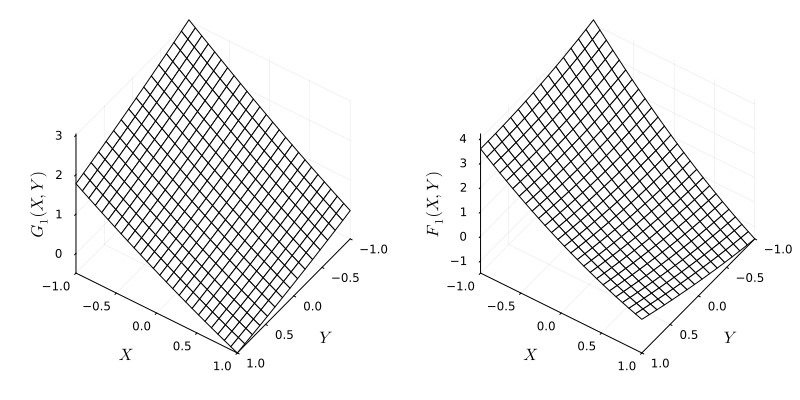

In [22]:
p1 = niceplot(Xs, Ys, G1_XY, L"$X$", L"$Y$", L"$G_{1}(X, Y)$", "fig/C_G1.pdf", yflip=true, size=quarsize)
p2 = niceplot(Xs, Ys, F1_XY, L"$X$", L"$Y$", L"$F_{1}(X, Y)$", "fig/C_F1.pdf", yflip=true, size=quarsize)
p = plot(p1, p2, size=fullsize12)

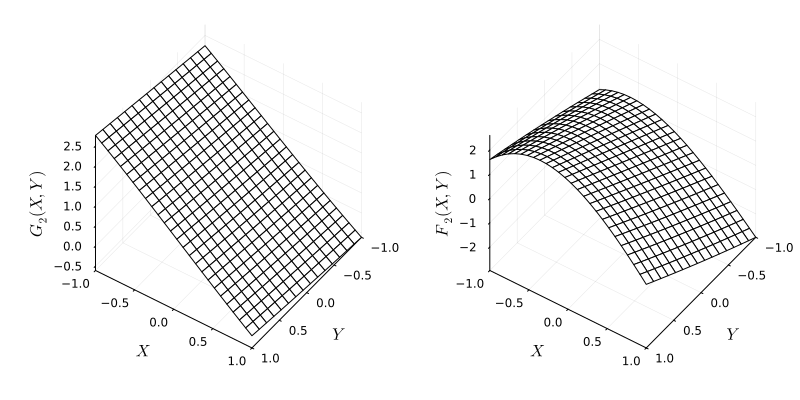

In [23]:
p1 = niceplot(Xs, Ys, G2_XY, L"$X$", L"$Y$", L"$G_{2}(X, Y)$", "fig/C_G2.pdf", yflip=true, size=quarsize)
p2 = niceplot(Xs, Ys, F2_XY, L"$X$", L"$Y$", L"$F_{2}(X, Y)$", "fig/C_F2.pdf", yflip=true, size=quarsize)
p = plot(p1, p2, size=fullsize12)

In [24]:
xs = LinRange(-1, 1, 25)
ys = LinRange(-1, 1, 16)
xys = [(x, y) for y in ys,x in xs];

In [25]:
g1(x, y) = G1_newton(x^2, y)
f1(x, y) = F1_newton(x^2, y)
g2(x, y) = G2_newton(x^2, y)
f2(x, y) = F2_newton(x^2, y)

g1_xy = map(xy -> g1(xy...), xys);
f1_xy = map(xy -> f1(xy...), xys);
g2_xy = map(xy -> g2(xy...), xys);
f2_xy = map(xy -> f2(xy...), xys);

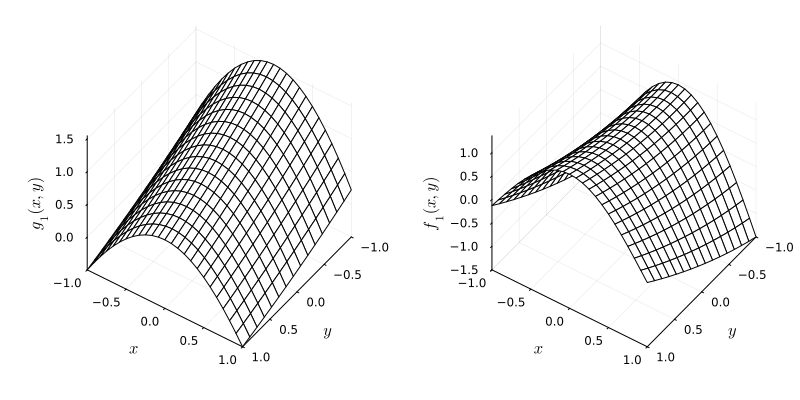

In [26]:
p1 = niceplot(xs, ys, g1_xy, L"$x$", L"$y$", L"$g_{1}(x, y)$", "fig/C_g1.pdf", yflip=true, size=quarsize)
p2 = niceplot(xs, ys, f1_xy, L"$x$", L"$y$", L"$f_{1}(x, y)$", "fig/C_f1.pdf", yflip=true, size=quarsize)
p = plot(p1, p2, size=fullsize12)

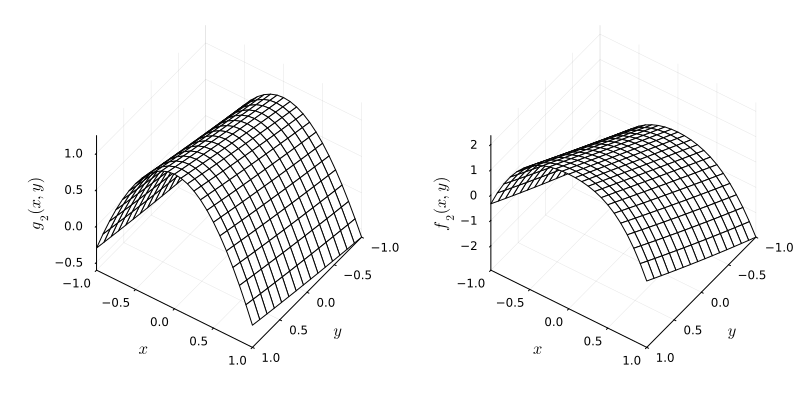

In [27]:
p3 = niceplot(xs, ys, g2_xy, L"$x$", L"$y$", L"$g_{2}(x, y)$", "fig/C_g2.pdf", yflip=true, size=quarsize)
p4 = niceplot(xs, ys, f2_xy, L"$x$", L"$y$", L"$f_{2}(x, y)$", "fig/C_f2.pdf", yflip=true, size=quarsize)
p = plot(p3, p4, size=fullsize12)

### 3 Numerical Domain Extensions

We have the following functional equations

\begin{align}
    a_1^{-1}G_1\big(G_1(a_1^2X, b_1Y)^2,F_1(a_1^2X, b_1Y)\big)
    &=G_2(X,Y)\quad\mbox{on $\Omega_2$},\\
    b_1^{-1}F_1\big(G_1(a_1^2X, b_1Y)^2,F_1(a_1^2X, b_1Y)\big)
    &=F_2(X,Y)\quad\mbox{on $\Omega_2$},\\
    a_2^{-1}G_2\big(G_2(a_2^2X, b_2Y)^2,F_2(a_2^2X, b_2Y)\big)
    &=G_1(X,Y)\quad\mbox{on $\Omega_1$}\\
    b_2^{-1}F_2\big(G_2(a_2^2X, b_2Y)^2,F_2(a_2^2X, b_2Y)\big)
    &=F_1(X,Y)\quad\mbox{on $\Omega_1$}.
\end{align}

We wish to find domains $\Omega_1,\Omega_2$ for which the following inclusions hold:

\begin{align}
\overline{\mbox{diag}(a_1^2, b_1)\Omega_2}
&\subset\Omega_1,\\
\overline{(G_1^2,F_1)\mbox{diag}(a_1^2, b_1)\Omega_2}
&\subset\Omega_1,\\
\overline{\mbox{diag}(a_2^2, b_2)\Omega_1}
&\subset\Omega_2,\\
\overline{(G_2^2,F_2)\mbox{diag}(a_2^2, b_2)\Omega_1}
&\subset\Omega_2.
\end{align}

These inclusions will ensure that the operators $T_1,T_2$ are well defined on the spaces $\mathscr{A}(\Omega_1)$ and $\mathscr{A}(\Omega_2)$.  Moreover, by insisting that the closures of the left-hand sides are contained in the relevant domains, we ensure that the maps have analytic extensions to strictly larger domains and that the derivatives $\mathfrak{D}T_1(P_1)$ and $\mathfrak{D}T_2(P_2)$ are compact.

### 3.1 Real Domain Extensions

In [28]:
function gridplot_1(values_for_x, values_for_y, col)
    plot!(values_for_x, values_for_y, legend = false, color=col)
    plot!(collect(transpose(values_for_x)),collect(transpose(values_for_y)), color=col)
end

gridplot_1 (generic function with 1 method)

In [29]:
function gridplot_2_combined(cX, rX, cY, rY, n, name)
    range_of_X = range(cX - rX, cX + rX, n)
    range_of_Y = range(cY - rY, cY + rY, n)
    
    X_values = collect(range_of_X)
    Y_values = collect(transpose(range_of_Y))
    
    X = X_values .+ Y_values.*0
    Y = Y_values .+ X_values.*0
    
    p = plot(aspect_ratio= :equal)
    gridplot_1(X,Y, :graY)

    a1 = G1_newton(G1_newton(0,0)^2,F1_newton(0,0))
    b1 = F1_newton(G1_newton(0,0)^2,F1_newton(0,0))    
    A1 = a1^2
    A1X, b1Y = A1*X, b1*Y
    gridplot_1(A1X, b1Y, :red)

    GAXbY_1, FAXbY_1 = G1_newton.(A1X, b1Y), F1_newton.(A1X, b1Y)
    X2_1, Y2_1 = GAXbY_1.^2, FAXbY_1
    gridplot_1(X2_1, Y2_1, :blue)

    a2 = G2_newton(G2_newton(0,0)^2,F2_newton(0,0))
    b2 = F2_newton(G2_newton(0,0)^2,F2_newton(0,0))    
    A2 = a2^2
    A2X, b2Y = A2*X, b2*Y
    gridplot_1(A2X, b2Y, :orange)

    GAXbY_2, FAXbY_2 = G2_newton.(A2X, b2Y), F2_newton.(A2X, b2Y)
    X2_2, Y2_2 = GAXbY_2.^2, FAXbY_2
    gridplot_1(X2_2, Y2_2, :green)
    
    # numerical real domain extension (NRDE)
    nrde1 = all(abs.(A1X.-cX) .< rX)
    nrde2 = all(abs.(b1Y.-cY) .< rY)
    nrde3 = all(abs.(X2_1.-cX) .< rX)
    nrde4 = all(abs.(Y2_1.-cY) .< rY)
    nrde5 = all(abs.(A2X.-cX) .< rX)
    nrde6 = all(abs.(b2Y.-cY) .< rY)
    nrde7 = all(abs.(X2_2.-cX) .< rX)
    nrde8 = all(abs.(Y2_2.-cY) .< rY)
    nrde = nrde1 && nrde2 && nrde3 && nrde4 && nrde5 && nrde6 && nrde7 && nrde8 #nrde = true/false

    savefig(p, name*".pdf")
    display(p)
    println(nrde)
end

gridplot_2_combined (generic function with 1 method)

### 3.2 Complex Domain Extensions

In [30]:
# plot identical sized 2d matrices of x and y values as a grid
function gridplot_new(x_vals, y_vals, col, style)
    plot!(x_vals, y_vals, color=col, linestyle=style)
    plot!(collect(transpose(x_vals)), collect(transpose(y_vals)), color=col, linestyle=style)
end

gridplot_new(x_vals, y_vals, col) = gridplot_new(x_vals, y_vals, col, :solid)

gridplot_new (generic function with 2 methods)

In [31]:
# assume that X is a 4d array for G(X,Y)
# for some function G,
# parameterised by r_X, theta_X, r_y, theta_y
function plot_bidisc(X)
    n1, n2, n3, n4 = size(X)

    # plot non-distinguished boundary
    if false
        for j=1:n1
            gridplot_new(real.(X[j,:,end,:]), imag.(X[j,:,end,:]), :gray)
        end
        for j=1:n2
            gridplot_new(real.(X[:,j,end,:]), imag.(X[:,j,end,:]), :gray)
        end
        for j=1:n3
            gridplot_new(real.(X[end,:,j,:]), imag.(X[end,:,j,:]), :gray)
        end
        for j=1:n4
            gridplot_new(real.(X[end,:,:,j]), imag.(X[end,:,:,j]), :gray)
        end
    end

    # plot toriodal shells
    for j=1:n1
       for k=1:n3
            if (j==n1 && k==n3)
                # distinguished boundary
                color = :blue
                gridplot_new(real.(X[j,:,k,:]), imag.(X[j,:,k,:]), color)
            elseif (j==n1 || k==n3)
                # boundary
                continue
            else
                # interior
                continue
            end
        end
    end
    gridplot_new(real.(X[end,:,1,1]), imag.(X[end,:,1,1]), :green)
    gridplot_new(real.(X[1,1,end,:]), imag.(X[1,1,end,:]), :green)
end

plot_bidisc (generic function with 1 method)

### 4 Functions Analytic with respect to a Polydisc

### 4.1 Isomorphism with respect to the new domain

In what follows, we seek locations for the centres $c_k,d_k$ of the bidiscs $\Omega_k=D(c_k,r_k)\times D(d_k,s_k)$.

The choice of centres (and radii) determines the structures of the norms on the resulting spaces $\mathscr{A}(\Omega_k)$.  In particular, good choices for the centres and radii will mean that the power series coefficients for our functions decay more quickly, allowing the proof to proceed with a lower truncation degree, and correspondingly that the error terms involved in bounding a composition $H\circ(G,F)$ remain manageable.

For the latter, it is important that the constant terms on functions $\widehat{G},\widehat{F}$ are as small as possible (recall that we write $G=\widehat{G}\circ\psi_\Omega$ and $F=\widehat{F}\circ\psi_\Omega$ for the relevant domain $\Omega$).

Consider the functional equations above, we note that suitable centres $(c_k,d_k)$ correspond to pairs of points in $\mathbb{C}^2$ that are exchanged by the inner maps that form roots of the outer maps.

We use a crude optimisation scheme to approximate these:

In [32]:
# Optimising domain centres

function domain_optimisation(g, f, cX, cY, h, steps)
    #for reference, following values were used for h and steps:
    #h = 0.5
    #steps = 50
    cXnew, cYnew = cX, cY
    while h > 1e-16
        abs_new = max(abs(g(cX,cY)), abs(f(cX,cY)))
        for X in RR.(LinRange(cX-h, cX+h, steps))
            for y in RR.(LinRange(cY-h, cY+h, steps))
                abs_current = max(abs(g(X,y)), abs(f(X,y)))
                if abs_current < abs_new
                    cXnew, cYnew, abs_new = X, y, abs_current
                end
            end
        end
        h = h/10
        cX, cY = cXnew, cYnew
        println(max(abs(g(cX,cY)), abs(f(cX,cY))), " ", cX, " ", cY)
    end
end

domain_optimisation (generic function with 1 method)

In [33]:
domain_optimisation(G1_newton, F1_newton, 0.5, 0.5, 0.5, 50)

0.012827244181557562 0.6530612244897959 0.5510204081632653
0.0004026077712033782 0.6459183673469386 0.5540816326530612
1.2917050396410446e-5 0.6462244897959182 0.5541836734693877
9.11275255854882e-6 0.6462346938775508 0.5542142857142855
1.3079431619988924e-6 0.6462275510204079 0.5542071428571427
7.17207000455744e-8 0.6462284693877548 0.5542074489795916
6.534657592816018e-9 0.646228520408163 0.5542074591836732
1.7309509381391308e-10 0.6462285234693875 0.5542074683673467
5.4857451914358535e-11 0.6462285233673467 0.5542074684693875
6.471823077447425e-12 0.6462285233775508 0.5542074684183671
8.703038290036602e-13 0.6462285233826528 0.5542074684234691
1.2212453270876722e-13 0.6462285233823466 0.5542074684221426
1.0436096431476471e-14 0.6462285233822751 0.5542074684221733
8.881784197001252e-16 0.6462285233822802 0.5542074684221682
0.0 0.6462285233822799 0.5542074684221691
0.0 0.6462285233822799 0.5542074684221691


In [34]:
domain_optimisation(G2_newton, F2_newton, 0.5, 0.5, 0.5, 50)

0.006547487323372625 0.7551020408163265 0.6530612244897959
0.0003862888002281739 0.7479591836734693 0.633673469387755
0.000119913324074572 0.7484693877551019 0.635
9.323831605678734e-6 0.7483571428571427 0.634704081632653
1.3418048927515969e-6 0.7483479591836733 0.6346826530612244
3.356453026626127e-8 0.7483480612244895 0.63468193877551
2.6456863366774996e-9 0.7483480306122445 0.6346818673469385
1.1662824039859743e-9 0.7483480275510199 0.6346818581632651
1.3021073108632208e-10 0.748348028673469 0.6346818611224487
9.653611243720661e-12 0.7483480287244894 0.6346818611530609
1.0167422459517184e-12 0.7483480287132649 0.6346818611214283
5.728750807065808e-14 0.7483480287141833 0.6346818611233671
4.218847493575595e-15 0.7483480287142139 0.6346818611234794
6.661338147750939e-16 0.7483480287142088 0.6346818611234661
2.220446049250313e-16 0.7483480287142092 0.6346818611234673
0.0 0.7483480287142095 0.6346818611234678


In [35]:
@everywhere cX1, cY1, cX2, cY2 = 0.6462285233822799, 0.5542074684221691, 0.7483480287142101, 0.6346818611234695

In [36]:
a1 = G1_newton(G1_newton(RR(0), RR(0))^2, F1_newton(RR(0), RR(0)))

-0.4999055883629153

In [37]:
a2 = G2_newton(G2_newton(RR(0), RR(0))^2, F2_newton(RR(0), RR(0)))

-0.30468711815058525

In [38]:
b1 = F1_newton(G1_newton(RR(0), RR(0))^2, F1_newton(RR(0), RR(0)))

-0.1307721783283431

In [39]:
b2 = F2_newton(G2_newton(RR(0), RR(0))^2, F2_newton(RR(0), RR(0)))

-0.345696547173167

In [40]:
@everywhere rX1, rY1, rX2, rY2 = 1.6, 1.38, 1.25, 1.95

In [41]:
function plot_box(cx, rx, cy, ry, color, label)
    plot!([cx-rx, cx+rx, cx+rx, cx-rx, cx-rx], [cy-ry, cy-ry, cy+ry, cy+ry, cy-ry], color=color, label=label, linestyle=:dash)
end

function plot_grid(Xy, color, label)
    plot!(first.(Xy), last.(Xy), color=color, label=:none)
    Xy_T = [Xy[k,j] for j=1:size(Xy)[1],k=1:size(Xy)[2]]
    plot!(first.(Xy_T), last.(Xy_T), color=color, label=:none)
    annotate!(first(Xy[1,1]), last(Xy[1,1]), text(label, :black, :right, :bottom, 12))
end

function domain_extension(G_1, F_1, G_2, F_2, pos_cx, pos_rx, pos_cy, pos_ry, neg_cx, neg_rx, neg_cy, neg_ry)
    a_1 = G_1(G_1(0.0, 0.0)^2, F_1(0.0, 0.0))
    b_1 = F_1(G_1(0.0, 0.0)^2, F_1(0.0, 0.0))
    a_2 = G_2(G_2(0.0, 0.0)^2, F_2(0.0, 0.0))
    b_2 = F_2(G_2(0.0, 0.0)^2, F_2(0.0, 0.0))

    # consider places where the pos maps are applied in the functional equations

    # take X,Y in the neg domain
    neg_X = LinRange(neg_cx-neg_rx, neg_cx+neg_rx, 10)
    neg_y = LinRange(neg_cy-neg_ry, neg_cy+neg_ry, 10)
    neg_Xy = [(X, y) for X in neg_X, y in neg_y]

    neg_a2Xby = map(Xy->(a_1^2*Xy[1],b_1*Xy[2]), neg_Xy)
    neg_QGF_a2Xby = map(Xy->(G_1(Xy...)^2,F_1(Xy...)), neg_a2Xby)

    p1 = plot(tickdir=:out, size=halfsize, left_margin=5Plots.mm, bottom_margin=2Plots.mm)
    xlabel!(L"$X_1$")
    ylabel!(L"$Y_1$")
    plot_box(pos_cx, pos_rx, pos_cy, pos_ry, :black, :none)
    plot_grid(neg_a2Xby, :red, L"$(a_1^2X_2,b_1Y_2)$")
    plot_grid(neg_QGF_a2Xby, :blue, L"$(G_1^2,F_1)(a_1^2X_2,b_1Y_2)$")

    # consider places where the neg maps are applied in the functional equations

    # take X,Y in the pos domain
    pos_X = LinRange(pos_cx-pos_rx, pos_cx+pos_rx, 10)
    pos_y = LinRange(pos_cy-pos_ry, pos_cy+pos_ry, 10)
    pos_Xy = [(X, y) for X in pos_X, y in pos_y]
        
    pos_a2Xby = map(Xy->(a_2^2*Xy[1],b_2*Xy[2]), pos_Xy)
    pos_QGF_a2Xby = map(Xy->(G_2(Xy...)^2,F_2(Xy...)), pos_a2Xby)

    p2 = plot(tickdir=:out, size=halfsize, left_margin=5Plots.mm, bottom_margin=2Plots.mm)
    xlabel!(L"$X_2$")
    ylabel!(L"$Y_2$")
    plot_box(neg_cx, neg_rx, neg_cy, neg_ry, :black, :none)
    plot_grid(pos_a2Xby, :red, L"$(a_2^2X_1,b_2Y_1)$")
    plot_grid(pos_QGF_a2Xby, :blue, L"$(G_2^2,F_2)(a_2^2X_1,b_2Y_1)$")

    plot(p1, p2, size=fullsize12)
end

domain_extension (generic function with 1 method)

In [42]:
function numerical_complex_domain_extension_double_domain_4_radii(
    gp, fp, gn, fn,
    cX1, cX2, rX1, rX2, cY1, cY2, rY1, rY2,
    n, prefix, do_plot)

    # number of elements in discretisation
    n1, n2, n3, n4 = n+1, 6n, n+1, 6n
    
    # sampling radial and angular parameters
    r1 = reshape(range(0, 1, n1), (n1, 1, 1, 1))
    t1 = reshape(range(0, 1, n2).*2pi, (1, n2, 1, 1))
    r2 = reshape(range(0, 1, n3), (1, 1, n3, 1))
    t2 = reshape(range(0, 1, n4).*2pi, (1, 1, 1, n4))

    # grid of points on bidisc domain 1
    Xp = (cX1 .+ rX1 .* r1 .* cos.(t1)) .+ (rX1 .* r1 .* sin.(t1)) .* 1im;
    yp = (cY1 .+ rY1 .* r2 .* cos.(t2)) .+ (rY1 .* r2 .* sin.(t2)) .* 1im;
    
    # grid of points on bidisc domain 2
    Xn = (cX2 .+ rX2 .* r1 .* cos.(t1)) .+ (rX2 .* r1 .* sin.(t1)) .* 1im;
    yn = (cY2 .+ rY2 .* r2 .* cos.(t2)) .+ (rY2 .* r2 .* sin.(t2)) .* 1im;
    
    # start with domain 2 and check images lie in domain 1
    X0_2, y0_2 = Xn, yn
    a1 = gp(gp(RR(0),RR(0))^2, fp(RR(0),RR(0)))
    b1 = fp(gp(RR(0),RR(0))^2, fp(RR(0),RR(0)))
    A1 = a1^2
    X1_1, y1_1 = A1X, b1y = A1 .* X0_2, b1 .* y0_2
    gAXby_1, fAXby_1 = gp.(A1X, b1y), fp.(A1X, b1y)
    X2_1, y2_1 = gAXby_1.^2, fAXby_1
    
    # start with domain 1 and check images lie in domain 2
    X0_1, y0_1 = Xp, yp
    a2 = gn(gn(RR(0),RR(0))^2, gn(RR(0),RR(0)))
    b2 = fn(gn(RR(0),RR(0))^2, gn(RR(0),RR(0)))
    A2 = a2^2
    X1_2, y1_2 = A2X, b2y = A2 .* X0_1, b2 .* y0_1
    gAXby_2, fAXby_2 = gn.(A2X, b2y), fn.(A2X, b2y)
    X2_2, y2_2 = gAXby_2.^2, fAXby_2
  
    # estimate wiggle room
    f1 = abs.(X1_1 .- cX1) ./ rX1
    f2 = abs.(y1_1 .- cY1) ./ rY1
    f3 = abs.(X2_1 .- cX1) ./ rX1
    f4 = abs.(y2_1 .- cY1) ./ rY1
    f5 = abs.(X1_2 .- cX2) ./ rX2
    f6 = abs.(y1_2 .- cY2) ./ rY2
    f7 = abs.(X2_2 .- cX2) ./ rX2
    f8 = abs.(y2_2 .- cY2) ./ rY2
    aif = max(maximum.([f1, f2, f3, f4, f5, f6, f7, f8])...)
    
    # numerical complex domain extension (NCDE)
    ncde1 = all(f1 .< 1)
    ncde2 = all(f2 .< 1)
    ncde3 = all(f3 .< 1)
    ncde4 = all(f4 .< 1)
    ncde5 = all(f5 .< 1)
    ncde6 = all(f6 .< 1)
    ncde7 = all(f7 .< 1)
    ncde8 = all(f8 .< 1)
    ncde = ncde1 && ncde2 && ncde3 && ncde4 && ncde5 && ncde6 && ncde7 && ncde8
    
    #maps applied to GAXby^2, FAXby are blue (distinguished boundary), green (boundary) and orange.
    if do_plot
        fontsize=16
        m=1.1
        
        pX_1 = plot(left_margin=5Plots.mm, aspect_ratio= :equal, legend=false, tickdir=:out)
      
        #gridplot_new(real.(X0_1[:,:,1,1]), imag.(X0_1[:,:,1,1]), :grey, :dash) #interior of +domain
        gridplot_new(real.(X0_1[end,:,1,1]), imag.(X0_1[end,:,1,1]), :grey) #exterior of +domain
        gridplot_new(real.(X1_1[:,:,1,1]), imag.(X1_1[:,:,1,1]), :red) #scaled
        plot_bidisc(X2_1)
        xlabel!(L"$\mathrm{Re}(X_{1})$")
        ylabel!(L"$\mathrm{Im}(X_{1})$")
        #annotate!(cX1, -rX1, text(L"D(c_1,r_1)", :top, fontsize))
        plot!(xlims=[cX1-m*rX1, cX1+m*rX1], ylims=[-m*rX1,m*rX1])

        pX_2 = plot(left_margin=5Plots.mm, aspect_ratio= :equal, legend=false, tickdir=:out)
        #gridplot_new(real.(X0_2[:,:,1,1]), imag.(X0_2[:,:,1,1]), :grey, :dash) #interior of -domain
        gridplot_new(real.(X0_2[end,:,1,1]), imag.(X0_2[end,:,1,1]), :grey) #exterior of -domain
        gridplot_new(real.(X1_2[:,:,1,1]), imag.(X1_2[:,:,1,1]), :red)
        plot_bidisc(X2_2)
        xlabel!(L"$\mathrm{Re}(X_{2})$")
        ylabel!(L"$\mathrm{Im}(X_{2})$")
        #annotate!(cX2, -rX2, text(L"D(c_2,r_2)", :top, fontsize))    
        plot!(xlims=[cX2-m*rX2, cX2+m*rX2], ylims=[-m*rX2,m*rX2])
            
        py_1 = plot(aspect_ratio= :equal, legend=false, tickdir=:out)
        #gridplot_new(real.(y0_1[1,1,:,:]), imag.(y0_1[1,1,:,:]), :grey, :dash) #interior of +domain
        gridplot_new(real.(y0_1[1,1,end,:]), imag.(y0_1[1,1,end,:]), :grey) #exterior of +domain
        gridplot_new(real.(y1_1[1,1,:,:]), imag.(y1_1[1,1,:,:]), :red)
        plot_bidisc(y2_1)
        xlabel!(L"$\mathrm{Re}(Y_{1})$")
        ylabel!(L"$\mathrm{Im}(Y_{1})$")
        #annotate!(cY1, -rY1, text(L"D(d_1,s_1)", :top, fontsize))    
        plot!(xlims=[cY1-m*rY1, cY1+m*rY1], ylims=[-m*rY1,m*rY1])
        
        py_2 = plot(aspect_ratio= :equal, legend=false, tickdir=:out)
        #gridplot_new(real.(y0_2[1,1,:,:]), imag.(y0_2[1,1,:,:]), :grey, :dash) #interior of -domain
        gridplot_new(real.(y0_2[1,1,end,:]), imag.(y0_2[1,1,end,:]), :grey) #exterior of -domain
        gridplot_new(real.(y1_2[1,1,:,:]), imag.(y1_2[1,1,:,:]), :red)
        plot_bidisc(y2_2)
        xlabel!(L"$\mathrm{Re}(Y_{2})$")
        ylabel!(L"$\mathrm{Im}(Y_{2})$")
        #annotate!(cY2, -rY2, text(L"D(d_2,s_2)", :top, fontsize))    
        plot!(xlims=[cY2-m*rY2, cY2+m*rY2], ylims=[-m*rY2,m*rY2])
        
        p1 = plot(pX_1, py_1, layout=(1,2), legend=false, size=fullsize12)
        p2 = plot(pX_2, py_2, layout=(1,2), legend=false, size=fullsize12)
        display(p1)
        display(p2)

        savefig(p1, prefix*"_Omega1.pdf")
        savefig(p2, prefix*"_Omega2.pdf")
    end
    ncde, aif #, (norm1_1, norm2_1, norm1_2, norm2_2)
end

numerical_complex_domain_extension_double_domain_4_radii (generic function with 1 method)

### Complex domain extension for unit polydisc domains

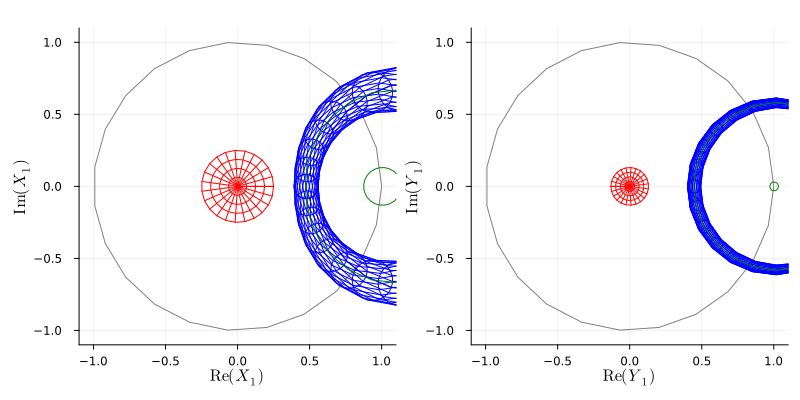

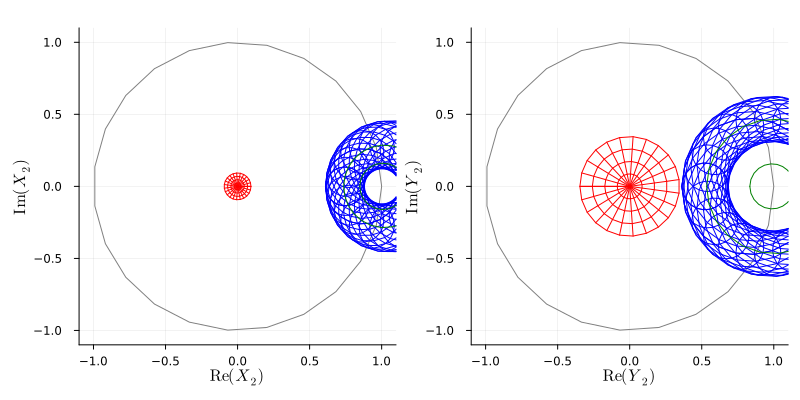

(false, 1.9394729521281495)

In [43]:
numerical_complex_domain_extension_double_domain_4_radii(
    V_newton...,
    0, 0, 1, 1, 0, 0, 1, 1,
    4, "fig/C_de_fail", true)

### Real domain extension for unit polydisc domains

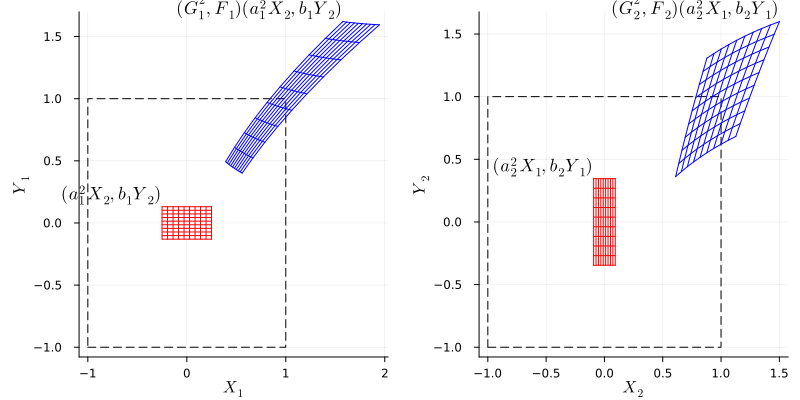

In [44]:
p = domain_extension(V_newton..., 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0)
savefig(p, "fig/C_de_real_omega0.pdf")
p

In [45]:
function theta(G, F, c_for_X, c_for_y)
    a = G(G(RR(0),RR(0))^2, F(RR(0),RR(0)))
    b = F(G(RR(0),RR(0))^2, F(RR(0),RR(0)))
    A = a^2
    (G(A*c_for_X, b*c_for_y)^2, F(A*c_for_X, b*c_for_y))
end

theta (generic function with 1 method)

In [46]:
@everywhere Ω1 = [cX1, cY1], [rX1, rY1]

In [47]:
@everywhere Ω2 = [cX2, cY2], [rX2, rY2]

In [48]:
X_from_unit_1 = Poly2([cX1 0; rX1 0])
y_from_unit_1 = Poly2([cY1 rY1; 0 0])

X_from_unit_2 = Poly2([cX2 0; rX2 0])
y_from_unit_2 = Poly2([cY2 rY2; 0 0])

Poly2([0.6346818611234695 1.95 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0])

In [49]:
# Re-express the pair that resulted from the Newton method
# but this time with separate domains for positive and negative pairs

G1_Ω1 = Poly2D(Ω1..., G1_newton(X_from_unit_1, y_from_unit_1));
F1_Ω1 = Poly2D(Ω1..., F1_newton(X_from_unit_1, y_from_unit_1));

G2_Ω2 = Poly2D(Ω2..., G2_newton(X_from_unit_2, y_from_unit_2));
F2_Ω2 = Poly2D(Ω2..., F2_newton(X_from_unit_2, y_from_unit_2));

In [50]:
P1_Ω1 = (G1_Ω1, F1_Ω1);
P2_Ω2 = (G2_Ω2, F2_Ω2);

In [51]:
@everywhere begin

#for 1 map of 2 variables
phi1omega(g::Poly2D) = tri_phi1(g.p) 
phi1omegapos_inv(c::Vector{RR}) = Poly2D(Ω1..., tri_phi1_inv(c))
phi1omeganeg_inv(c::Vector{RR}) = Poly2D(Ω2..., tri_phi1_inv(c))

#for 2 maps of 2 variables
phi2omega(gf::Tuple{Poly2D, Poly2D}) = [phi1omega(gf[1]); phi1omega(gf[2])] 
phi2omegapos_inv(c::Vector{RR}) = (phi1omegapos_inv(c[1:div(length(c), 2)]), phi1omegapos_inv(c[div(length(c), 2)+1:end]))
phi2omeganeg_inv(c::Vector{RR}) = (phi1omeganeg_inv(c[1:div(length(c), 2)]), phi1omeganeg_inv(c[div(length(c), 2)+1:end]))

#for a pair of pairs of maps of 2 variables each
phi4omega(gfplusminus::Tuple{Poly2D, Poly2D, Poly2D, Poly2D}) = [phi1omega(gfplusminus[1]); phi1omega(gfplusminus[2]); phi1omega(gfplusminus[3]); phi1omega(gfplusminus[4])]
phi4omega_11_22_inv(c) = (phi1omegapos_inv(c[1:div(length(c), 4)]), phi1omegapos_inv(c[div(length(c), 4)+1:div(length(c), 2)]), phi1omeganeg_inv(c[div(length(c), 2)+1:3*div(length(c), 4)]), phi1omeganeg_inv(c[3*div(length(c), 4)+1:end]))   
phi4omega_pn_np_inv(c) = (phi1omegapos_inv(c[1:div(length(c), 4)]), phi1omeganeg_inv(c[div(length(c), 4)+1:div(length(c), 2)]), phi1omeganeg_inv(c[div(length(c), 2)+1:3*div(length(c), 4)]), phi1omegapos_inv(c[3*div(length(c), 4)+1:end]))   
end

In [52]:
V_Ω = (P1_Ω1..., P2_Ω2...)
ST_V_Ω, SDT_V_Ω = ST_and_SDT(V_Ω)

((Poly2D([0.6462285233822799, 0.5542074684221691], [1.6, 1.38], Poly2([-4.194867793905385e-16 -0.49667248700964217 … 1.073547591773867e-28 1.832770802482992e-29; -1.726712316004361 0.30632793376526746 … 1.0241489564387596e-27 0.0; … ; -2.498876796044454e-22 3.071630325675366e-22 … 0.0 0.0; 1.7736318804066238e-23 0.0 … 0.0 0.0])), Poly2D([0.6462285233822799, 0.5542074684221691], [1.6, 1.38], Poly2([2.474653340343007e-16 0.9189001757909422 … 1.4558930008542808e-26 -8.613171906985299e-29; -2.5089038972342004 0.9240749944148514 … 9.397826613473629e-27 0.0; … ; -4.555783528970359e-21 1.1257217164895709e-20 … 0.0 0.0; 8.829983554505757e-22 0.0 … 0.0 0.0])), Poly2D([0.7483480287142101, 0.6346818611234695], [1.25, 1.95], Poly2([-2.399090733032349e-16 0.3712534561852822 … 8.55705154882351e-29 3.6800495097737644e-30; -1.858966691849156 -0.21086569887053566 … -1.7276322604897601e-28 0.0; … ; -9.778094983955593e-20 -7.319767919241738e-21 … 0.0 0.0; -4.794529066616474e-21 0.0 … 0.0 0.0])), Poly2D([

In [53]:
using Serialization

filename = "$(prefix)GF12_omega_newton.jls"

if use_precomputed
    G1_Ω1_newton, F1_Ω1_newton, G2_Ω2_newton, F2_Ω2_newton = deserialize(filename)
else
    G1_Ω1_newton, F1_Ω1_newton, G2_Ω2_newton, F2_Ω2_newton = newton_F(V_Ω, F_and_DF, phi4omega, phi4omega_11_22_inv, tri_basis_size_4)
    serialize(filename, (G1_Ω1_newton, F1_Ω1_newton, G2_Ω2_newton, F2_Ω2_newton))
end

0 4.9035081887735125e-12
1 4.6392872655945364e-14
2 5.067980349580949e-14
process ended


### Complex domain extension for new domains

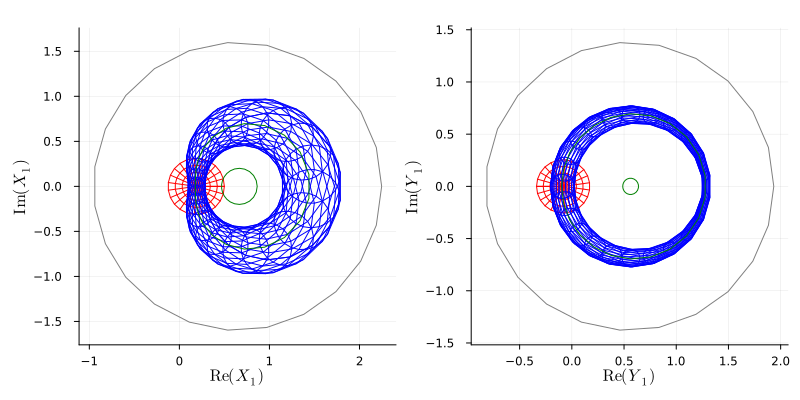

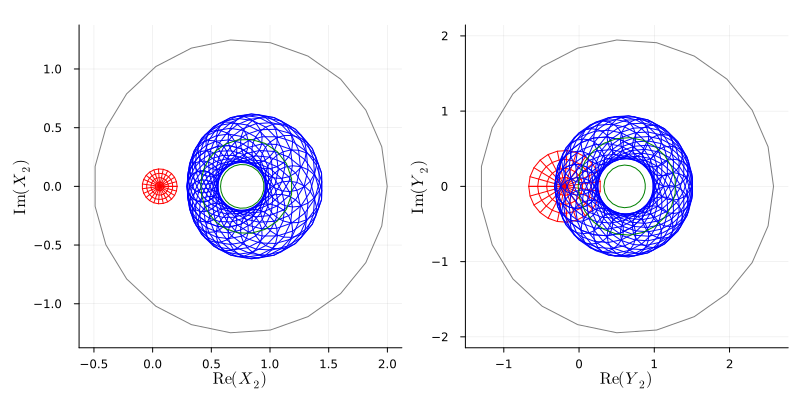

(true, 0.7184537987226047)

In [54]:
numerical_complex_domain_extension_double_domain_4_radii(
    G1_Ω1_newton, F1_Ω1_newton, G2_Ω2_newton, F2_Ω2_newton,
    cX1, cX2, rX1, rX2, cY1, cY2, rY1, rY2,
    4, "fig/C_de", true)

### Real domain extension for new domains

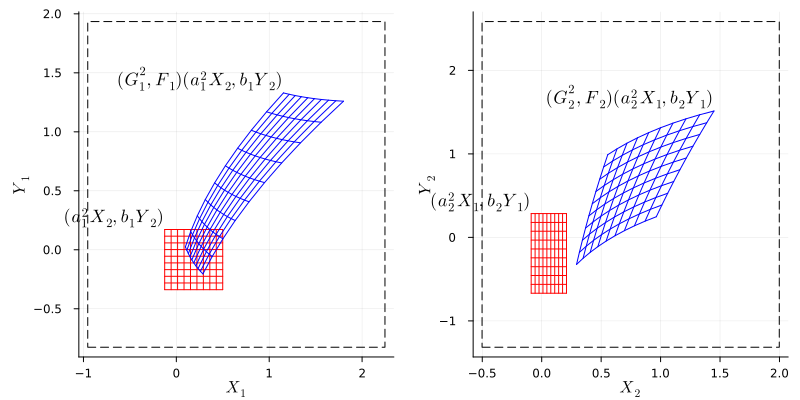

In [55]:
p = domain_extension(G1_Ω1_newton, F1_Ω1_newton, G2_Ω2_newton, F2_Ω2_newton, cX1, rX1, cY1, rY1, cX2, rX2, cY2, rY2)
savefig(p, "fig/C_de_real_omega12.pdf")
p

In [56]:
G1_Ω1_newton.p.coeffs[1,1], F1_Ω1_newton.p.coeffs[1,1], G2_Ω2_newton.p.coeffs[1,1], F2_Ω2_newton.p.coeffs[1,1]

(3.2857435102004807e-16, 8.4989141989006615e-16, -1.2450065509609816e-15, -3.5553277191733903e-16)

In [57]:
P1_Ω1_newton = (G1_Ω1_newton, F1_Ω1_newton)

(Poly2D([0.6462285233822799, 0.5542074684221691], [1.6, 1.38], Poly2([3.2857435102004807e-16 -0.4966724870096395 … 1.0735417508320178e-28 1.8327745203256408e-29; -1.7267123160043625 0.30632793376526596 … 1.0241487544843542e-27 0.0; … ; -2.498206816569006e-22 3.069636901780207e-22 … 0.0 0.0; 1.771444223317085e-23 0.0 … 0.0 0.0])), Poly2D([0.6462285233822799, 0.5542074684221691], [1.6, 1.38], Poly2([8.4989141989006615e-16 0.9189001757909434 … 1.4558930340064825e-26 -8.613186093958511e-29; -2.508903897234203 0.9240749944148468 … 9.39781861300555e-27 0.0; … ; -4.5491179847331135e-21 1.1237393995187704e-20 … 0.0 0.0; 8.80822563351827e-22 0.0 … 0.0 0.0])))

In [58]:
P2_Ω2_newton = (G2_Ω2_newton, F2_Ω2_newton)

(Poly2D([0.7483480287142101, 0.6346818611234695], [1.25, 1.95], Poly2([-1.2450065509609816e-15 0.37125345618528044 … 8.557051283167234e-29 3.6800489578143505e-30; -1.858966691849156 -0.21086569887053522 … -1.7276317875048437e-28 0.0; … ; -9.842998887158936e-20 -9.259584990771192e-21 … 0.0 0.0; -4.457417634280908e-21 0.0 … 0.0 0.0])), Poly2D([0.7483480287142101, 0.6346818611234695], [1.25, 1.95], Poly2([-3.5553277191733903e-16 2.7507133627598126 … 1.4255188477712209e-27 -1.0570057769620443e-28; -4.039229940714665 -0.27573555309261466 … 9.307751414151009e-27 0.0; … ; 5.217589727029208e-18 1.3006161562015937e-17 … 0.0 0.0; -1.4423492635908437e-18 0.0 … 0.0 0.0])))

In [59]:
V_Ω_newton = (P1_Ω1_newton..., P2_Ω2_newton...)

(Poly2D([0.6462285233822799, 0.5542074684221691], [1.6, 1.38], Poly2([3.2857435102004807e-16 -0.4966724870096395 … 1.0735417508320178e-28 1.8327745203256408e-29; -1.7267123160043625 0.30632793376526596 … 1.0241487544843542e-27 0.0; … ; -2.498206816569006e-22 3.069636901780207e-22 … 0.0 0.0; 1.771444223317085e-23 0.0 … 0.0 0.0])), Poly2D([0.6462285233822799, 0.5542074684221691], [1.6, 1.38], Poly2([8.4989141989006615e-16 0.9189001757909434 … 1.4558930340064825e-26 -8.613186093958511e-29; -2.508903897234203 0.9240749944148468 … 9.39781861300555e-27 0.0; … ; -4.5491179847331135e-21 1.1237393995187704e-20 … 0.0 0.0; 8.80822563351827e-22 0.0 … 0.0 0.0])), Poly2D([0.7483480287142101, 0.6346818611234695], [1.25, 1.95], Poly2([-1.2450065509609816e-15 0.37125345618528044 … 8.557051283167234e-29 3.6800489578143505e-30; -1.858966691849156 -0.21086569887053522 … -1.7276317875048437e-28 0.0; … ; -9.842998887158936e-20 -9.259584990771192e-21 … 0.0 0.0; -4.457417634280908e-21 0.0 … 0.0 0.0])), Poly2D

### Estimates for Inner Composition Norms

For inner composition norms (i.e., scaling norms) we have on $\Omega_1$:

\begin{align}
(G_2^2,F_2)\circ\mathrm{diag}(a_2^2,b_2)
&= (\widehat{G}_2^2,\widehat{F}_2)\circ\left[\psi_2\circ\mathrm{diag}(a_2^2,b_2)\circ\psi_1^{-1}\right]\circ\psi_1.
\end{align}

We note that the map in the square braces is given by

\begin{align}
(X,Y)
&\mapsto\left(
\frac{(a_2^2c_1-c_2)+(a_2^2r_1)X}{r_2},
\frac{(b_2d_1-d_2)+(b_2s_1)Y}{s_2}
\right).
\end{align}

Note that $(\widehat{G}_2^2,\widehat{F}_2)\in \mathscr{A}(\Omega_0)^2$ where $\Omega_0=D(0,1)\times D(0,1)$. We require that the map in square braces also lies in $\mathscr{A}(\Omega_0)^2$ so that the leftmost composition is well-defined in $\mathscr{A}(\Omega_0)^2$. Thus we require the following condition on the $\ell_1$ norms of the above

$$
\mathrm{max}\left(
\frac{1}{r_2}|a_2^2c_1-c_2|+\frac{r_1}{r_2}|a_2|^2,
\frac{1}{s_2}|b_2d_1-d_2|+\frac{s_1}{s_2}|b_2|
\right)<1.
$$

In [60]:
(abs(a2^2*cX1-cX2)+abs(a2^2*rX1))/rX2

0.6695125430785059

In [61]:
(abs(b2*cY1-cY2)+abs(b2*rY1))/rY2

0.6683747202428543

Similarly, we have on $\Omega_2$:

\begin{align}
(G_1^2,F_1)\circ\mathrm{diag}(a_1^2,b_1)
&= (\widehat{G}_1^2,\widehat{F}_1)\circ\left[\psi_1\circ\mathrm{diag}(a_1^2,b_1)\circ\psi_2^{-1}\right]\circ\psi_2.
\end{align}

We require the following condition on the $\ell_1$ norms of the square bracketed map above

$$
\mathrm{max}\left(
\frac{1}{r_1}|a_1^2c_2-c_1|+\frac{r_2}{r_1}a_1^2,
\frac{1}{s_1}|b_1d_2-d_1|+\frac{s_2}{s_1}|b_1|
\right)<1.
$$

In [62]:
(abs(a1^2*cX2-cX1)+abs(a1^2*rX2))/rX1

0.4822463493071094

In [63]:
(abs(b1*cY2-cY1)+abs(b1*rY2))/rY1

0.6465303954253923

### Estimates for Outer Composition Norms

For outer composition norms we have on $\Omega_1$:

\begin{align}
&{}
(G_2,F_2)\circ(G_2^2,F_2)\circ\mathrm{diag}(a_2^2,b_2)\\
&= 
(\widehat{G}_2,\widehat{F}_2)\circ\left[\psi_2
    \circ(G_2^2,F_2)
    \circ\mathrm{diag}(a_2^2,b_2)\circ\psi_1^{-1}\right]\circ\psi_1.
\end{align}

Similarly, on $\Omega_2$:

\begin{align}
&{}
(G_1,F_1)\circ(G_1^2,F_1)\circ\mathrm{diag}(a_1^2,b_1)\\
&= 
(\widehat{G}_1,\widehat{F}_1)\circ\left[\psi_1
    \circ(G_1^2,F_1)
    \circ\mathrm{diag}(a_1^2,b_1)\circ\psi_2^{-1}\right]\circ\psi_2.
\end{align}

In [64]:
X_Ω1 = Poly2D(Ω1..., X_from_unit_1)
y_Ω1 = Poly2D(Ω1..., y_from_unit_1)
X_Ω2 = Poly2D(Ω1..., X_from_unit_2)
y_Ω2 = Poly2D(Ω1..., y_from_unit_2)

Poly2D([0.6462285233822799, 0.5542074684221691], [1.6, 1.38], Poly2([0.6346818611234695 1.95 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0]))

In [65]:
G2_a22Xb2y = G2_Ω2_newton(a2^2*X_Ω1, b2*y_Ω1)
F2_a22Xb2y = F2_Ω2_newton(a2^2*X_Ω1, b2*y_Ω1)
abs(((G2_a22Xb2y*G2_a22Xb2y)-cX2)/rX2), abs(((F2_a22Xb2y)-cY2)/rY2)

(0.5612114664413348, 0.49947634726647044)

In [66]:
G1_a12Xb1y = G1_Ω1_newton(a1^2*X_Ω2, b1*y_Ω2)
F1_a12Xb1y = F1_Ω1_newton(a1^2*X_Ω2, b1*y_Ω2)
abs(((G1_a12Xb1y*G1_a12Xb1y)-cX1)/rX1), abs(((F1_a12Xb1y)-cY1)/rY1)

(0.7210594040432386, 0.6209573629833619)

### Visualising the good approximate two-cycle maps

In [67]:
cX1, cY1, cX2, cY2

(0.6462285233822799, 0.5542074684221691, 0.7483480287142101, 0.6346818611234695)

In [68]:
rX1, rY1, rX2, rY2

(1.6, 1.38, 1.25, 1.95)

In [69]:
X1s = LinRange(cX1-rX1, cX1+rX1, 26)
Y1s = LinRange(cY1-rY1, cY1+rY1, 16)
X1Y1s = [(x, y) for y in Y1s,x in X1s];
X2s = LinRange(cX2-rX2, cX2+rX2, 26)
Y2s = LinRange(cY2-rY2, cY2+rY2, 16)
X2Y2s = [(x, y) for y in Y2s,x in X2s];

In [70]:
G1_XY = map(xy -> G1_Ω1_newton(xy...), X1Y1s);
F1_XY = map(xy -> F1_Ω1_newton(xy...), X1Y1s);
G2_XY = map(xy -> G2_Ω2_newton(xy...), X2Y2s);
F2_XY = map(xy -> F2_Ω2_newton(xy...), X2Y2s);

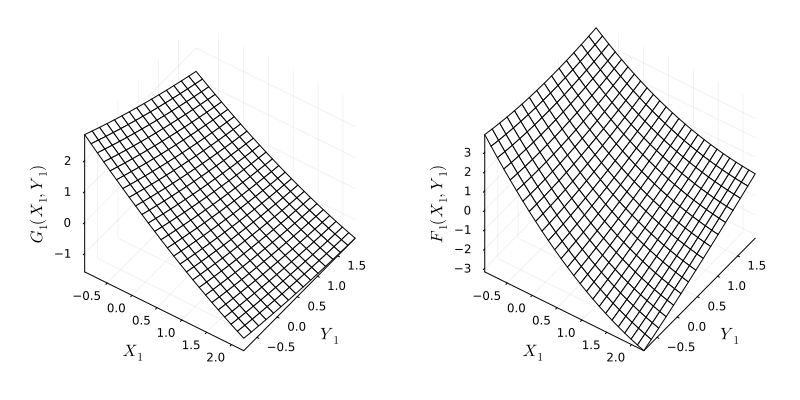

In [71]:
p1 = niceplot(X1s, Y1s, G1_XY, L"$X_1$", L"$Y_1$", L"$G_1(X_1,Y_1)$", "fig/C_G1_good.pdf")
p2 = niceplot(X1s, Y1s, F1_XY, L"$X_1$", L"$Y_1$", L"$F_1(X_1,Y_1)$", "fig/C_F1_good.pdf")
p = plot(p1, p2, size=fullsize12)

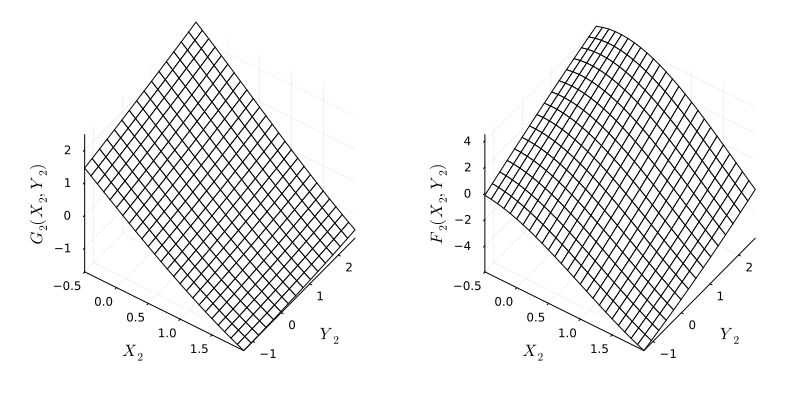

In [72]:
p3 = niceplot(X2s, Y2s, G2_XY, L"$X_2$", L"$Y_2$", L"$G_2(X_2,Y_2)$", "fig/C_G2_good.pdf")
p4 = niceplot(X2s, Y2s, F2_XY, L"$X_2$", L"$Y_2$", L"$F_2(X_2,Y_2)$", "fig/C_F2_good.pdf")
p = plot(p3, p4, size=fullsize12)

In [73]:
function GF_recurrence(XY, index)
    X, Y = XY
    if index == 1
        G1k, F1k, G2k, F2k = G1_Ω1_newton, F1_Ω1_newton, G2_Ω2_newton, F2_Ω2_newton
        ck, rk, dk, sk = cX1, rX1, cY1, rY1
    else
        G1k, F1k, G2k, F2k = G2_Ω2_newton, F2_Ω2_newton, G1_Ω1_newton, F1_Ω1_newton       
        ck, rk, dk, sk = cX2, rX2, cY2, rY2
    end
    if (abs(X-ck)<rk) && (abs(Y-dk)<sk)
        return G1k(X, Y), F1k(X, Y)
    else
        ak = G2k(G2k(0.0, 0.0)^2, F2k(0.0, 0.0))
        bk = F2k(G2k(0.0, 0.0)^2, F2k(0.0, 0.0))
        X1k, Y1k = GF_recurrence((ak^2*X, bk*Y), 3-index)
        X2k, Y2k = GF_recurrence((X1k^2, Y1k), 3-index)
        X3k, Y3k = ak^-1*X2k, bk^-1*Y2k
        return X3k, Y3k
    end
end

GF_recurrence (generic function with 1 method)

In [74]:
mult = 48
X1s = LinRange(0, +2*mult, 45)
Y1s = LinRange(-mult, +mult, 45)
X1Y1s = [(x, y) for y in Y1s,x in X1s];
X2s = LinRange(0, +2*mult, 45)
Y2s = LinRange(-mult, +mult, 45)
X2Y2s = [(x, y) for y in Y2s,x in X2s];

In [75]:
G1F1_XY = map(xy -> GF_recurrence(xy, 1), X1Y1s);
G2F2_XY = map(xy -> GF_recurrence(xy, 2), X2Y2s);

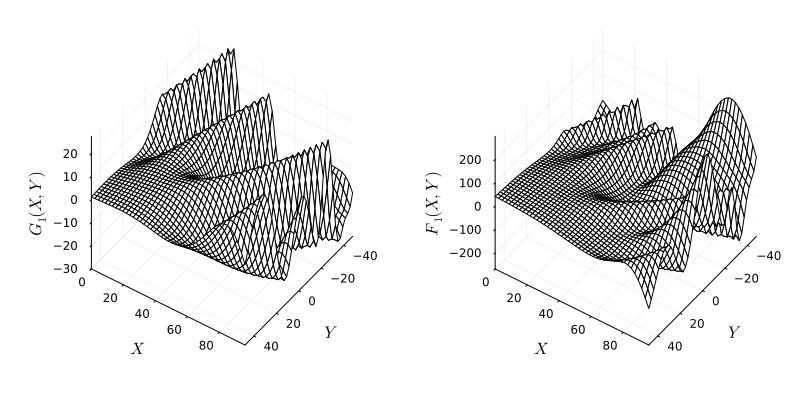

In [76]:
p1 = niceplot(X1s, Y1s, map(xy->xy[1], (G1F1_XY)), L"$X$", L"$Y$", L"$G_1(X, Y)$", "fig/C_G1_recurrence.pdf", yflip=true)
p2 = niceplot(X1s, Y1s, map(xy->xy[2], (G1F1_XY)), L"$X$", L"$Y$", L"$F_1(X, Y)$", "fig/C_F1_recurrence.pdf", yflip=true)
p = plot(p1, p2, size=fullsize12)

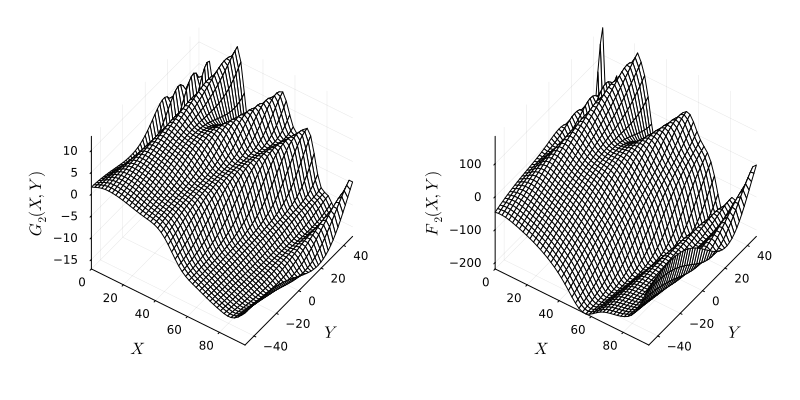

In [77]:
p1 = niceplot(X2s, Y2s, map(xy->xy[1], (G2F2_XY)), L"$X$", L"$Y$", L"$G_2(X, Y)$", "fig/C_G2_recurrence.pdf")
p2 = niceplot(X2s, Y2s, map(xy->xy[2], (G2F2_XY)), L"$X$", L"$Y$", L"$F_2(X, Y)$", "fig/C_F2_recurrence.pdf")
p = plot(p1, p2, size=fullsize12)

In [78]:
mult = 1.0 #8.25
X1s = LinRange(-mult, +mult, 30)
Y1s = LinRange(-mult^2, +mult^2, 30)
X1Y1s = [(x^2, y) for y in Y1s,x in X1s];
X2s = LinRange(-mult, +mult, 30)
Y2s = LinRange(-mult^2, +mult^2, 30)
X2Y2s = [(x^2, y) for y in Y2s,x in X2s];

In [79]:
G1F1_XY = map(xy -> GF_recurrence(xy, 1), X1Y1s);
G2F2_XY = map(xy -> GF_recurrence(xy, 2), X2Y2s);

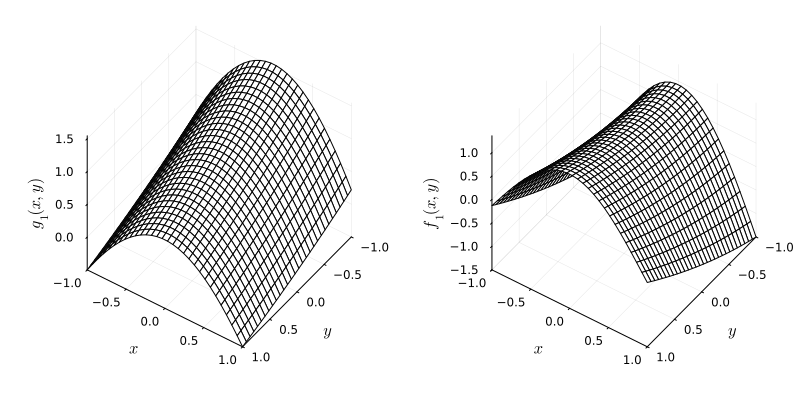

In [80]:
p1 = niceplot(X1s, Y1s, map(xy->xy[1], (G1F1_XY)), L"$x$", L"$y$", L"$g_1(x, y)$", "fig/C_g1_small.pdf", yflip=true)#, zlims=(-20,30))
p2 = niceplot(X1s, Y1s, map(xy->xy[2], (G1F1_XY)), L"$x$", L"$y$", L"$f_1(x, y)$", "fig/C_f1_small.pdf", yflip=true)#, zlims=(-100,180))
p = plot(p1, p2, size=fullsize12)    

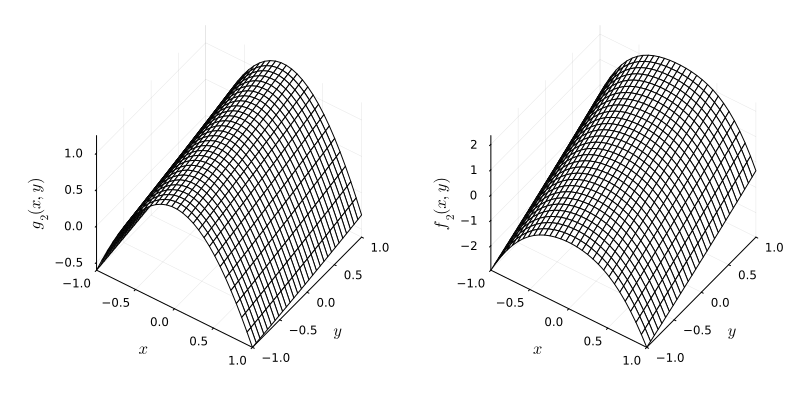

In [81]:
p1 = niceplot(X2s, Y2s, map(xy->xy[1], (G2F2_XY)), L"$x$", L"$y$", L"$g_2(x, y)$", "fig/C_g2_small.pdf")#, zlims=(-20,30))
p2 = niceplot(X2s, Y2s, map(xy->xy[2], (G2F2_XY)), L"$x$", L"$y$", L"$f_2(x, y)$", "fig/C_f2_small.pdf")
p = plot(p1, p2, size=fullsize12)

In [82]:
mult = 8.25
X1s = LinRange(-mult, +mult, 45)
Y1s = LinRange(-mult^2, +mult^2, 45)
X1Y1s = [(x^2, y) for y in Y1s,x in X1s];
X2s = LinRange(-mult, +mult, 45)
Y2s = LinRange(-mult^2, +mult^2, 45)
X2Y2s = [(x^2, y) for y in Y2s,x in X2s];

In [83]:
G1F1_XY = map(xy -> GF_recurrence(xy, 1), X1Y1s);
G2F2_XY = map(xy -> GF_recurrence(xy, 2), X2Y2s);

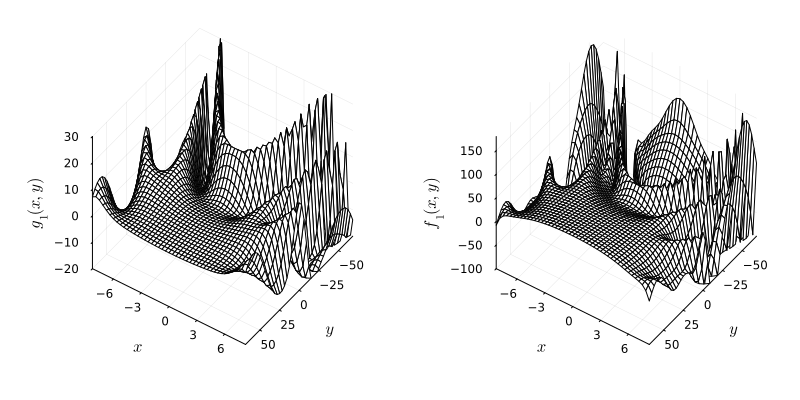

In [84]:
p1 = niceplot(X1s, Y1s, map(xy->xy[1], (G1F1_XY)), L"$x$", L"$y$", L"$g_1(x, y)$", "fig/C_g1_recurrence.pdf", yflip=true, zlims=(-20,30))
p2 = niceplot(X1s, Y1s, map(xy->xy[2], (G1F1_XY)), L"$x$", L"$y$", L"$f_1(x, y)$", "fig/C_f1_recurrence.pdf", yflip=true, zlims=(-100,180))
p = plot(p1, p2, size=fullsize12)    

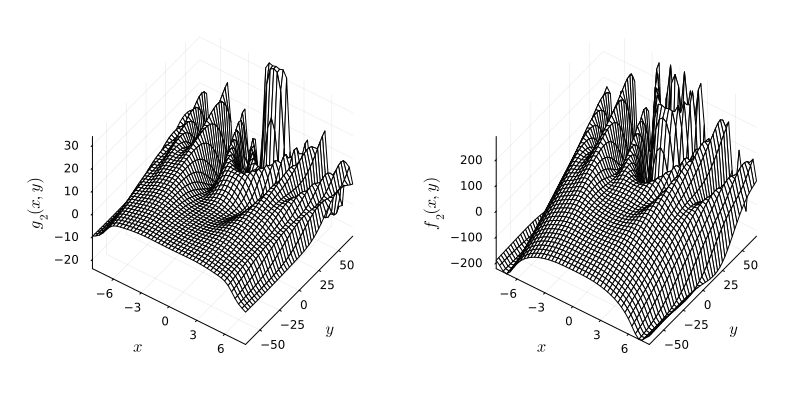

In [85]:
p1 = niceplot(X2s, Y2s, map(xy->xy[1], (G2F2_XY)), L"$x$", L"$y$", L"$g_2(x, y)$", "fig/C_g2_recurrence.pdf")#, zlims=(-20,30))
p2 = niceplot(X2s, Y2s, map(xy->xy[2], (G2F2_XY)), L"$x$", L"$y$", L"$f_2(x, y)$", "fig/C_f2_recurrence.pdf")
p = plot(p1, p2, size=fullsize12)

In [86]:
FV_Ω_newton, DFV_Ω_newton = F_and_DF(V_Ω_newton)

((Poly2D([0.6462285233822799, 0.5542074684221691], [1.6, 1.38], Poly2([6.639751849618208e-16 -6.106226635438361e-16 … -1.502191953756204e-42 2.4382593279251817e-43; 2.220446049250313e-15 -6.106226635438361e-16 … -5.0222536961401444e-42 0.0; … ; 1.349467514743986e-35 -1.7444336166202747e-35 … 0.0 0.0; -1.0226800852153901e-36 0.0 … 0.0 0.0])), Poly2D([0.6462285233822799, 0.5542074684221691], [1.6, 1.38], Poly2([-1.3161134190923688e-15 -1.6653345369377348e-15 … -2.92725644003597e-40 5.5267211432970785e-42; 3.552713678800501e-15 -1.9984014443252818e-15 … 1.363183146095182e-40 0.0; … ; 2.2945649728051052e-34 -6.0937627146627384e-34 … 0.0 0.0; -5.002903957099656e-35 0.0 … 0.0 0.0])), Poly2D([0.7483480287142101, 0.6346818611234695], [1.25, 1.95], Poly2([-1.2267101164254856e-15 1.1657341758564144e-15 … 4.4618239935119343e-39 -1.4509205448942553e-39; -1.7763568394002505e-15 -1.1379786002407855e-15 … -1.5636248784322039e-40 0.0; … ; -3.117599097476838e-33 -3.851859888774472e-34 … 0.0 0.0; -1.075

In [87]:
T1_P1_Ω1_newton, DT1_P1_Ω1_newton = T_and_DT(P1_Ω1_newton, coordinate_maps(P2_Ω2_newton))
T2_P2_Ω2_newton, DT2_P2_Ω2_newton = T_and_DT(P2_Ω2_newton, coordinate_maps(P1_Ω1_newton))

((Poly2D([0.6462285233822799, 0.5542074684221691], [1.6, 1.38], Poly2([-3.3540083394177266e-16 -0.4966724870096389 … 1.0735417508320328e-28 1.8327745203256164e-29; -1.7267123160043647 0.30632793376526657 … 1.0241487544843592e-27 0.0; … ; -2.498206816569141e-22 3.0696369017803814e-22 … 0.0 0.0; 1.7714442233171873e-23 0.0 … 0.0 0.0])), Poly2D([0.6462285233822799, 0.5542074684221691], [1.6, 1.38], Poly2([2.166004838982435e-15 0.9189001757909451 … 1.4558930340065118e-26 -8.613186093959064e-29; -2.5089038972342066 0.9240749944148487 … 9.397818613005414e-27 0.0; … ; -4.549117984733343e-21 1.1237393995188313e-20 … 0.0 0.0; 8.80822563351877e-22 0.0 … 0.0 0.0]))), var"#DTP#15"{Poly2D, Poly2D, Poly2D, Poly2D, Poly2D, Poly2D, Poly2D, Poly2D, Poly2D, Float64, Float64, Float64, Float64, Poly2D, Poly2D, Poly2D, Poly2D}(Poly2D([0.7483480287142101, 0.6346818611234695], [1.25, 1.95], Poly2([1.4106222373127244 0.12978635142771616 … -1.3009301870302083e-27 0.0; -0.14140284773980238 0.20236305857681047 … 

In [88]:
abs(T1_P1_Ω1_newton[1].p - P2_Ω2_newton[1].p)

7.023547216940013e-15

In [89]:
abs(T1_P1_Ω1_newton[2].p - P2_Ω2_newton[2].p)

1.956443414391855e-14

In [90]:
abs(T2_P2_Ω2_newton[1].p - P1_Ω1_newton[1].p)

5.3959157484803426e-15

In [91]:
abs(T2_P2_Ω2_newton[2].p - P1_Ω1_newton[2].p)

1.4408975546606455e-14

In [92]:
using Serialization

filename = "$(prefix)Matrix_for_P1_newton.jls"

if use_precomputed
    Matrix_for_P1_newton = deserialize(filename)
else
    Matrix_for_P1_newton = matrix_elements(DT1_P1_Ω1_newton, phi2omega, phi2omegapos_inv, tri_basis_size_2)
    serialize(filename, (Matrix_for_P1_newton))
end

3380000

In [93]:
using Serialization

filename = "$(prefix)Matrix_for_P2_newton.jls"

if use_precomputed
    Matrix_for_P2_newton = deserialize(filename)
else
    Matrix_for_P2_newton = matrix_elements(DT2_P2_Ω2_newton, phi2omega, phi2omeganeg_inv, tri_basis_size_2)
    serialize(filename, (Matrix_for_P2_newton))
end

3380000

### Numerical spectrum

Here, we estimate the spectra of $\mathfrak{D}(T^2)(P_1)$ and $\mathfrak{D}(T^2)(P_2)$.

In [94]:
M1 = matrix_elements(DT1_P1_Ω1_newton, phi2omega, phi2omegapos_inv, tri_basis_size_2)
M2 = matrix_elements(DT2_P2_Ω2_newton, phi2omega, phi2omeganeg_inv, tri_basis_size_2)

650×650 Matrix{Float64}:
 -7.82001       2.99492      -0.183403     …   3.65576e-6    6.88132e-6
 -5.38678      -0.359938      1.26794          3.04001e-6    5.90098e-6
  2.72513      -0.456696      0.171539        -1.43186e-6   -2.63416e-6
 -0.201939      0.0555674    -0.0842533        1.03784e-7    1.88705e-7
 -0.00257254   -0.000448108   0.0020977        1.15417e-9    2.2933e-9
  0.00134865   -0.000266438   0.000275897  …  -6.5674e-10   -1.21847e-9
 -0.000135481   3.12797e-5   -3.84403e-5       6.62299e-11   1.22121e-10
  7.80044e-6   -2.0999e-6     3.02828e-6      -3.83538e-12  -7.02427e-12
 -7.63424e-8    4.36099e-8   -1.08386e-7       3.98533e-14   6.95122e-14
 -2.80916e-8    6.05792e-9   -4.67199e-9       1.35535e-14   2.50861e-14
  2.42993e-9   -6.36951e-10   7.81077e-10  …  -1.1801e-15   -2.16885e-15
 -7.71466e-11   2.42581e-11  -3.92085e-11      3.7762e-17    6.8848e-17
 -2.50928e-12   3.89159e-13   2.1878e-13       1.18722e-18   2.22296e-18
  ⋮                               

In [95]:
using GenericSchur

val21, vec21 = GenericSchur.eigen(M2*M1)
reverse(sort(val21, by=x->abs(x)))[1:10]

10-element Vector{ComplexF64}:
    92.43127088599141 + 0.0im
    22.12022805559153 + 0.0im
    4.192444205100753 + 0.0im
   0.9332555232316049 + 0.0im
   0.5131847824917183 + 0.0im
  0.19198978402559982 + 0.0im
 0.056016736870466495 + 0.0im
  0.04520749051443895 + 0.0im
  0.04520749051438458 + 0.0im
  0.03593613794163804 + 0.0im

In [96]:
val12, vec12 = GenericSchur.eigen(M1*M2)
reverse(sort(val12, by=x->abs(x)))[1:10]

10-element Vector{ComplexF64}:
    92.43127088599105 + 0.0im
   22.120228055591507 + 0.0im
    4.192444205100696 + 0.0im
   0.9332555232316093 + 0.0im
   0.5131847824916885 + 0.0im
  0.19198978402550937 + 0.0im
 0.056016736870401325 + 0.0im
 0.045207490514554804 + 0.0im
   0.0452074905144237 + 0.0im
  0.03593613794168157 + 0.0im

Remember we have defined

$$
\mathcal{T} := \mbox{diag}(T_1,T_2) = \left(\begin{array}{cc}T_1&0\\ 0&T_2\end{array}\right).
$$

Also

$$
\mathcal{F} := I - S\mathcal{T} = I - \left(\begin{array}{cc}0&T_2\\ T_1&0\end{array}\right).
$$

and so

$$
\mathfrak{D}\mathcal{F}(V) = I - \left(\begin{array}{cc}0&\mathfrak{D}T_2(P_2)\\ \mathfrak{D}T_1(P_1)&0\end{array}\right).
$$

In matrix form, we have

$$
\mathcal{F} = \left( \begin{array}{c|c}
I & 0  \\
\hline
0 & I
\end{array} \right)
-  \left( \begin{array}{c|c}
0 & T_2  \\
\hline
T_1 & 0
\end{array} \right)
= \left( \begin{array}{c|c}
I & -T_2  \\
\hline
-T_1 & I
\end{array} \right)\begin{array}{c}\#_1\\ \#_2\end{array}.
$$

This gives the matrix of the derivative to be

$$
\mathfrak{D}\mathcal{F}(P_1, P_2) = \left( \begin{array}{c|c}
I & -\mathfrak{D}T_2(P_2)  \\
\hline
-\mathfrak{D}T_1(P_1) & I
\end{array} \right)\begin{array}{c}\#_1\\ \#_2\end{array}.
$$

We use the approximations for the polynomial parts

$$
\mathfrak{D}T_1(P_1) \simeq \Delta_1 = \left( \begin{array}{c|c}
\Delta_{1,PP} & 0  \\
\hline
0 & 0
\end{array} \right)\begin{array}{c}\mathscr{P}\\ \mathscr{H}\end{array}
$$

and 

$$
\mathfrak{D}T_2(P_2) \simeq \Delta_2 = \left( \begin{array}{c|c}
\Delta_{2,PP} & 0  \\
\hline
0 & 0
\end{array} \right)\begin{array}{c}\mathscr{P}\\ \mathscr{H}\end{array}.
$$

So this means

$$
\mathfrak{D}\mathcal{F}(P_1, P_2) = \left( \begin{array}{c|c}
I & -\mathfrak{D}T_2(P_2)  \\
\hline
-\mathfrak{D}T_1(P_1) & I
\end{array} \right)
= \left( \begin{array}{cc|cc}
I & 0 & -\Delta_{2,PP} & 0 \\
0 & I & 0 & 0 \\ 
\hline
- \Delta_{1,PP} & 0 & I & 0 \\
0 & 0 & 0 & I
\end{array} \right)\begin{array}{c}\mathscr{P}\#_1\\ \mathscr{H}\#_1\\ \mathscr{P}\#_2\\ \mathscr{H}\#_2\end{array}.
$$

Here we have first partitioned into the first and second pair of maps (1 and 2) and then the polynomial and higher order parts ($\mathscr{P}$ and $\mathscr{H}$).

Now, we first partition into the polynomial and higher order parts ($\mathscr{P}$ and $\mathscr{H}$) and then the first and second pair of maps (1 and 2) to get:

$$
\mathfrak{D}\mathcal{F}(P_1, P_2) = \left( \begin{array}{c|c}
I & -\mathfrak{D}T_2(P_2)  \\
\hline
-\mathfrak{D}T_1(P_1) & I
\end{array} \right)
= \left( \begin{array}{cc|cc}
I &-\Delta_{2,PP} & 0 & 0 \\
- \Delta_{1,PP} & I & 0 & 0 \\ 
\hline
0 & 0 & I & 0 \\
0 & 0 & 0 & I
\end{array} \right)
\begin{array}{c}\mathscr{P}\#_1\\ \mathscr{P}\#_2\\ \mathscr{H}\#_1\\ \mathscr{H}\#_2\end{array}
=: I-\Delta.
$$

This is in block diagonal form (that is the reason for using this form).

We want the inverse: 

$$
\Gamma := (I-\Delta)^{-1} 
= \left( \begin{array}{c|c}
\left( \begin{array}{cc} 
I &-\Delta_{2,PP} \\
- \Delta_{1,PP} & I
\end{array} \right) ^{-1}
&
\left( \begin{array}{cc} 
0 & 0 \\
0 & 0
\end{array} \right) \\
\hline
\left( \begin{array}{cc} 
0 & 0 \\
0 & 0
\end{array} \right)
&
\left( \begin{array}{cc} 
I & 0 \\
0 & I
\end{array} \right)
\end{array} \right)
\begin{array}{c}\mathscr{P}\#_1\\ \mathscr{P}\#_2\\ \mathscr{H}\#_1\\ \mathscr{H}\#_2\end{array}
=
\left(\begin{array}{c|c}\Gamma_{PP}&0\\ \hline 0&I\end{array}\right)
\begin{array}{c}\mathscr{P}\\ \mathscr{H}\end{array}.
$$

We have

$$
\Gamma V = \left( \begin{array}{c|c}
\left( \begin{array}{cc} 
I &-\Delta_{2,PP} \\
- \Delta_{1,PP} & I
\end{array} \right) ^{-1}
&\left( \begin{array}{cc} 
0 & 0 \\
0 & 0
\end{array} \right) \\
\hline
\left( \begin{array}{cc} 
0 & 0 \\
0 & 0
\end{array} \right)
&\left( \begin{array}{cc} 
I & 0 \\
0 & I
\end{array}\right) \end{array} \right)
\left(
\begin{array}{c}
\mathcal{P}P_{1} \\
\mathcal{P}P_{2} \\
\mathcal{H}P_{1} \\
\mathcal{H}P_{2}
\end{array}
\right)
$$

Let $V = (G_1, F_1, G_2, F_2)$ where each of the 4 maps are divided into their polynomial, higher order and error parts. We will use the following partition:
$$
\Gamma (V) = [\Gamma_{PP} V_P] + [V_H] + [\Gamma_{PP} \mathcal{P} V_E + \mathcal{H} V_E],
$$
i.e. the first part will go into the polynomial part, the second part will go into the higher order part and the remaining will go into the error part.

In [97]:
using Serialization

filename = "$(prefix)Matrix_for_V1_newton.jls"

if use_precomputed
    Matrix_for_V_newton = deserialize(filename)
else
    Matrix_for_V_newton = matrix_elements(DFV_Ω_newton, phi4omega, phi4omega_11_22_inv, tri_basis_size_4)
    serialize(filename, (Matrix_for_V_newton))
end

13520000

## Rigorous bounds

In [98]:
@everywhere begin
    include("rigorous/Interval.jl")   # Intervals (bounding reals)
    include("rigorous/Rectangle.jl")  # Rectangles (bounding complex numbers)
    include("rigorous/Trunc2.jl")     # Truncated power series
    include("rigorous/StdBall2.jl")   # Standard function balls (w.r.t. unit polydisc)
    include("rigorous/Domain2.jl")    # Domain / Polydisc
    include("rigorous/Ball2.jl")      # Nonstandard function balls (w.r.t. general polydisc) 
end

In [99]:
G1_Ω1_trunc = Trunc2(Interval.(G1_Ω1_newton.p.coeffs))
F1_Ω1_trunc = Trunc2(Interval.(F1_Ω1_newton.p.coeffs))
G2_Ω2_trunc = Trunc2(Interval.(G2_Ω2_newton.p.coeffs))
F2_Ω2_trunc = Trunc2(Interval.(F2_Ω2_newton.p.coeffs))

Trunc2(Interval[Interval(-3.5553277191733903e-16, -3.5553277191733903e-16) Interval(2.7507133627598126, 2.7507133627598126) … Interval(1.4255188477712209e-27, 1.4255188477712209e-27) Interval(-1.0570057769620443e-28, -1.0570057769620443e-28); Interval(-4.039229940714665, -4.039229940714665) Interval(-0.27573555309261466, -0.27573555309261466) … Interval(9.307751414151009e-27, 9.307751414151009e-27) Interval(0.0, 0.0); … ; Interval(5.217589727029208e-18, 5.217589727029208e-18) Interval(1.3006161562015937e-17, 1.3006161562015937e-17) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(-1.4423492635908437e-18, -1.4423492635908437e-18) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)])

In [100]:
@everywhere begin
    
dom1 = Domain2(
    (Interval(cX1), Interval(cY1)),
    (Interval(rX1), Interval(rY1)))

dom2 = Domain2(
    (Interval(cX2), Interval(cY2)),
    (Interval(rX2), Interval(rY2)))

end

In [101]:
B_G1_0 = Ball2(dom1, StdBall2(G1_Ω1_trunc, RR(0), RR(0)))
B_F1_0 = Ball2(dom1, StdBall2(F1_Ω1_trunc, RR(0), RR(0)))
B_P1_0 = (B_G1_0, B_F1_0)

B_G2_0 = Ball2(dom2, StdBall2(G2_Ω2_trunc, RR(0), RR(0)))
B_F2_0 = Ball2(dom2, StdBall2(F2_Ω2_trunc, RR(0), RR(0)))
B_P2_0 = (B_G2_0, B_F2_0)

(Ball2(Domain2((Interval(0.7483480287142101, 0.7483480287142101), Interval(0.6346818611234695, 0.6346818611234695)), (Interval(1.25, 1.25), Interval(1.95, 1.95))), StdBall2(Trunc2(Interval[Interval(-1.2450065509609816e-15, -1.2450065509609816e-15) Interval(0.37125345618528044, 0.37125345618528044) … Interval(8.557051283167234e-29, 8.557051283167234e-29) Interval(3.6800489578143505e-30, 3.6800489578143505e-30); Interval(-1.858966691849156, -1.858966691849156) Interval(-0.21086569887053522, -0.21086569887053522) … Interval(-1.7276317875048437e-28, -1.7276317875048437e-28) Interval(0.0, 0.0); … ; Interval(-9.842998887158936e-20, -9.842998887158936e-20) Interval(-9.259584990771192e-21, -9.259584990771192e-21) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(-4.457417634280908e-21, -4.457417634280908e-21) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)]), Interval(0.0, 0.0), Interval(0.0, 0.0))), Ball2(Domain2((Interval(0.7483480287142101, 0.7483480287142101), Interval(0.6346818

In [102]:
function coordinate_maps((G,F))
    (cXG, cyG), (rXG, ryG) = G.dom.c, G.dom.r
    (cXF, cyF), (rXF, ryF) = F.dom.c, F.dom.r
    @assert G.dom == F.dom

    coeffsX = Interval.([cXG RR(0); rXG RR(0)])
    coeffsy = Interval.([cyG ryG; RR(0) RR(0)])
    id_X = Ball2(G.dom, StdBall2(Trunc2(coeffsX), RR(0), RR(0)))
    id_Y = Ball2(G.dom, StdBall2(Trunc2(coeffsy), RR(0), RR(0)))
    id_X, id_Y
end

coordinate_maps (generic function with 3 methods)

In [103]:
id_X_1, id_Y_1 = coordinate_maps((B_G1_0, B_F1_0))

(Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799), Interval(0.5542074684221691, 0.5542074684221691)), (Interval(1.6, 1.6), Interval(1.38, 1.38))), StdBall2(Trunc2(Interval[Interval(0.6462285233822799, 0.6462285233822799) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(1.6, 1.6) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0); … ; Interval(0.0, 0.0) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(0.0, 0.0) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)]), Interval(0.0, 0.0), Interval(0.0, 0.0))), Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799), Interval(0.5542074684221691, 0.5542074684221691)), (Interval(1.6, 1.6), Interval(1.38, 1.38))), StdBall2(Trunc2(Interval[Interval(0.5542074684221691, 0.5542074684221691) Interval(1.38, 1.38) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(0.0, 0.0) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0); … ; Interval(0.0, 0.0) Interval(0.0, 0.0) …

In [104]:
id_X_2, id_Y_2 = coordinate_maps((B_G2_0, B_F2_0))

(Ball2(Domain2((Interval(0.7483480287142101, 0.7483480287142101), Interval(0.6346818611234695, 0.6346818611234695)), (Interval(1.25, 1.25), Interval(1.95, 1.95))), StdBall2(Trunc2(Interval[Interval(0.7483480287142101, 0.7483480287142101) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(1.25, 1.25) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0); … ; Interval(0.0, 0.0) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(0.0, 0.0) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)]), Interval(0.0, 0.0), Interval(0.0, 0.0))), Ball2(Domain2((Interval(0.7483480287142101, 0.7483480287142101), Interval(0.6346818611234695, 0.6346818611234695)), (Interval(1.25, 1.25), Interval(1.95, 1.95))), StdBall2(Trunc2(Interval[Interval(0.6346818611234695, 0.6346818611234695) Interval(1.95, 1.95) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(0.0, 0.0) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0); … ; Interval(0.0, 0.0) Interval(0.0, 

Recall we have

$$
\Delta_1 \simeq \mathfrak{D}T_1(P_1) = \left(\begin{array}{c|c}
\Delta_{1,PP} & 0\\
\hline
0 & 0
\end{array}\right),
$$ 

and 

$$
\Delta_2 \simeq \mathfrak{D}T_2(P_2) = \left(\begin{array}{c|c}
\Delta_{2,PP} & 0\\
\hline
0 & 0
\end{array}\right).
$$

The higher order parts are set to $0$ because we are considering approximations, which have only polynomial parts.

In [105]:
Δ_1_nonrig = Matrix_for_P1_newton #\Delta_{1,PP}
Δ_2_nonrig = Matrix_for_P2_newton #\Delta_{2,PP}

650×650 Matrix{Float64}:
 -7.82001       2.99492      -0.183403     …   3.65576e-6    6.88132e-6
 -5.38678      -0.359938      1.26794          3.04001e-6    5.90098e-6
  2.72513      -0.456696      0.171539        -1.43186e-6   -2.63416e-6
 -0.201939      0.0555674    -0.0842533        1.03784e-7    1.88705e-7
 -0.00257254   -0.000448108   0.0020977        1.15417e-9    2.2933e-9
  0.00134865   -0.000266438   0.000275897  …  -6.5674e-10   -1.21847e-9
 -0.000135481   3.12797e-5   -3.84403e-5       6.62299e-11   1.22121e-10
  7.80044e-6   -2.0999e-6     3.02828e-6      -3.83538e-12  -7.02427e-12
 -7.63424e-8    4.36099e-8   -1.08386e-7       3.98533e-14   6.95122e-14
 -2.80916e-8    6.05792e-9   -4.67199e-9       1.35535e-14   2.50861e-14
  2.42993e-9   -6.36951e-10   7.81077e-10  …  -1.1801e-15   -2.16885e-15
 -7.71466e-11   2.42581e-11  -3.92085e-11      3.7762e-17    6.8848e-17
 -2.50928e-12   3.89159e-13   2.1878e-13       1.18722e-18   2.22296e-18
  ⋮                               

We can also use the following single $\Gamma$:

$$
\Gamma = \left( \begin{array}{c|c}
\left( \begin{array}{cc} 
I &-\Delta_{2,PP} \\
- \Delta_{1,PP} & I
\end{array} \right) ^{-1}
&\left( \begin{array}{cc} 
0 & 0 \\
0 & 0
\end{array} \right) \\
\hline
\quad \quad \quad \left( \begin{array}{cc} 
0 & 0 \\
0 & 0
\end{array} \right)
\quad \quad \quad \quad \quad
&\left( \begin{array}{cc} 
I & 0 \\
0 & I
\end{array}\right) \end{array} \right),
$$

with

$$
\Gamma_{PP} = \left( \begin{array}{cc} 
I &-\Delta_{2,PP} \\
- \Delta_{1,PP} & I
\end{array} \right) ^{-1}.
$$

In [106]:
Γ_PP_nonrig_inv = [eye(tri_basis_size_2) -Δ_2_nonrig; -Δ_1_nonrig eye(tri_basis_size_2)]

1300×1300 Matrix{Float64}:
  1.0           0.0           0.0          …  -3.65576e-6   -6.88132e-6
  0.0           1.0           0.0             -3.04001e-6   -5.90098e-6
  0.0           0.0           1.0              1.43186e-6    2.63416e-6
  0.0           0.0           0.0             -1.03784e-7   -1.88705e-7
  0.0           0.0           0.0             -1.15417e-9   -2.2933e-9
  0.0           0.0           0.0          …   6.5674e-10    1.21847e-9
  0.0           0.0           0.0             -6.62299e-11  -1.22121e-10
  0.0           0.0           0.0              3.83538e-12   7.02427e-12
  0.0           0.0           0.0             -3.98533e-14  -6.95122e-14
  0.0           0.0           0.0             -1.35535e-14  -2.50861e-14
  0.0           0.0           0.0          …   1.1801e-15    2.16885e-15
  0.0           0.0           0.0             -3.7762e-17   -6.8848e-17
  0.0           0.0           0.0             -1.18722e-18  -2.22296e-18
  ⋮                             

In [107]:
Γ_PP_nonrig = inv(Γ_PP_nonrig_inv)

1300×1300 Matrix{Float64}:
  1.9073        0.605201      -2.48607      …  -1.1249e-7    -4.43659e-6
  3.91651      12.0548       -22.9795           1.83276e-6   -3.13202e-5
 -1.31584      -3.40655        8.32266         -4.68722e-7    1.04797e-5
  0.0966079     0.239482      -0.531538         3.03644e-8   -7.79355e-7
 -8.63225e-5    0.000413214    0.000309861      9.85089e-11   9.02003e-10
 -0.000465639  -0.00120202     0.00261047   …  -1.60829e-10   3.86073e-9
  5.07247e-5    0.000127599   -0.000282865      1.99647e-11  -4.20141e-10
 -3.08992e-6   -7.59485e-6     1.70016e-5      -1.57461e-12   2.49717e-11
  4.57376e-8    9.70532e-8    -2.34008e-7       7.12931e-14  -2.82274e-13
  9.50853e-9    2.46363e-8    -5.36615e-8       3.13948e-16  -8.74871e-14
 -8.82744e-10  -2.20437e-9     4.90005e-9   …  -3.94808e-16   7.81558e-15
  3.04833e-11   7.30362e-11   -1.66569e-10      4.27437e-17  -2.59795e-16
  6.88539e-13   1.93487e-12   -4.03408e-12     -2.87312e-18  -7.80646e-18
  ⋮             

In [108]:
#just to verify that they are inverses
sum(abs.(Γ_PP_nonrig * Γ_PP_nonrig_inv - eye(tri_basis_size_4)))

2.1640301973460704e-11

In [109]:
# check invertibility
include("rigorous/Gauss.jl")
#Γ_1_PP = Interval.(Γ_1_nonrig)
#I_Ginv = gauss([Γ_1_PP Interval.(eye(tri_basis_size_2))]);
#Ginv = I_Ginv[:,tri_basis_size_2+1:end];
#(Ginv * Γ_1_PP)[1:5,1:5]

gauss (generic function with 1 method)

In [110]:
# check invertibility of other matrix
#Γ_2_PP = Interval.(Γ_2_nonrig)
#I_Ginv_2 = gauss([Γ_2_PP Interval.(eye(tri_basis_size_2))]);
#Ginv_2 = I_Ginv_2[:,tri_basis_size_2+1:end];
#(Ginv_2 * Γ_2_PP)[1:5,1:5]

In [111]:
Γ_PP = Interval.(Γ_PP_nonrig)

1300×1300 Matrix{Interval}:
 Interval(1.9073, 1.9073)              …  Interval(-4.43659e-6, -4.43659e-6)
 Interval(3.91651, 3.91651)               Interval(-3.13202e-5, -3.13202e-5)
 Interval(-1.31584, -1.31584)             Interval(1.04797e-5, 1.04797e-5)
 Interval(0.0966079, 0.0966079)           Interval(-7.79355e-7, -7.79355e-7)
 Interval(-8.63225e-5, -8.63225e-5)       Interval(9.02003e-10, 9.02003e-10)
 Interval(-0.000465639, -0.000465639)  …  Interval(3.86073e-9, 3.86073e-9)
 Interval(5.07247e-5, 5.07247e-5)         Interval(-4.20141e-10, -4.20141e-10)
 Interval(-3.08992e-6, -3.08992e-6)       Interval(2.49717e-11, 2.49717e-11)
 Interval(4.57376e-8, 4.57376e-8)         Interval(-2.82274e-13, -2.82274e-13)
 Interval(9.50853e-9, 9.50853e-9)         Interval(-8.74871e-14, -8.74871e-14)
 Interval(-8.82744e-10, -8.82744e-10)  …  Interval(7.81558e-15, 7.81558e-15)
 Interval(3.04833e-11, 3.04833e-11)       Interval(-2.59795e-16, -2.59795e-16)
 Interval(6.88539e-13, 6.88539e-13)       In

In [112]:
filename = "$(prefix)Gamma_PP.jls"
serialize(filename, Γ_PP)

27040000

In [113]:
@everywhere begin

using Serialization
filename = "$(prefix)Gamma_PP.jls"
Γ_PP = deserialize(filename)

end

### Action of the linear operator

For generalisation, we will use $\Gamma$: 
Similar to the FQ system, the action of $\Gamma$ on the polynomial part will be $\Gamma_{PP}$ and the action on the higher order part will be $+I$. **Note the plus.** This gives the following:
\begin{align}
g = \Gamma(f_P+f_H+f_E)
&= \Gamma f_P + \Gamma f_H + \Gamma f_E\\
&= \Gamma_{PP} f_P + f_H + \Gamma (\mathcal{P}f_E + \mathcal{H}f_E)\\
&= \Gamma_{PP} f_P + f_H + \Gamma_{PP} \mathcal{P}f_E + \mathcal{H}f_E.
\end{align}

Let $g_P, g_H, g_E$ denote the different parts of $g = \Gamma f$. Though there are a few options that were discussed regarding where to put the polynomial part of the error term, we decided to use the below distribution:

\begin{align}
g_P &= \Gamma_{PP} f_P,\\
g_H &= f_H,\\
g_E &= \Gamma_{PP} \mathcal{P}f_E +\mathcal{H}f_E
\end{align}

using the bounds

\begin{align}
& \|g_H\|_1 \le \|f_H\|_1 = v_H, \\
& \|\mathcal{H}f_E\|_1 \le \|f_E\|_1 = v_E, \\
& \|g_E\|_1 \leq \|\Gamma_{PP}\mathcal{P}f_E\|_1 + \| \mathcal{H}f_E \|_1 \le \|\Gamma_{PP}\|_1 v_E + v_E,
\end{align}
We use the column-sum norm to make calculations involving $\Gamma_{PP}$ and $v_E$.

$$
\|g_E\|_1 \leq \|\Gamma_{PP}\mathcal{P}f_E\|_1 + \| \mathcal{H}f_E \|_1 \le \|\Gamma_{PP}\|_1 v_E + v_E = \max(\|\Gamma_{PP}\|_1,1)v_E
$$

Since $\mathcal{P}f_E$ and $\mathcal{H}f_E$ are disjoint, we have two extreme situations: all of $v_E$ is in $\mathcal{P}f_E$ or all or $v_E$ is in $\mathcal{H}f_E$. In the first case, the bound would be $\|g_E\|_1 \leq \|\Gamma_{PP}\mathcal{P}f_E\|_1 \leq \|\Gamma_{PP}\|_1 v_E$. In the second case, the bound would be $\|g_E\|_1 \leq \|\mathcal{H}f_E\|_1  \leq v_E$. Then we can linearly interpolate all the cases in between these extrema to get the convex hull.
We use the hull function for intervals instead of the maximum function. Also, we use the column-sum norm to evaluate $\Gamma_{PP}\mathcal{P}f_E$ with all 4 components of $f_E$ being the error part bounds of the 4 maps.

In [114]:
# Defining phi maps on Ball2 structure

@everywhere begin

#for 1 map of 2 variables
phi1omega(g::Ball2) = tri_phi1(g.std.t) 
phi1omegapos_inv(c::Vector{Interval}) = Ball2(dom1, StdBall2(tri_phi1_inv(c), Interval(0), Interval(0)))
phi1omeganeg_inv(c::Vector{Interval}) = Ball2(dom2, StdBall2(tri_phi1_inv(c), Interval(0), Interval(0)))

#for 2 maps of 2 variables
phi2omega(gf::Tuple{Ball2, Ball2}) = [phi1omega(gf[1]); phi1omega(gf[2])] 
phi2omegapos_inv(c::Vector{Interval}) = (phi1omegapos_inv(c[1:div(length(c), 2)]), phi1omegapos_inv(c[div(length(c), 2)+1:end]))
phi2omeganeg_inv(c::Vector{Interval}) = (phi1omeganeg_inv(c[1:div(length(c), 2)]), phi1omeganeg_inv(c[div(length(c), 2)+1:end]))

#for 4 maps of 2 variables
phi4omega(gf::Tuple{Ball2, Ball2, Ball2, Ball2}) = [phi1omega(gf[1]); phi1omega(gf[2]); phi1omega(gf[3]); phi1omega(gf[4])] 
phi4omega_11_22_inv(c) = (phi1omegapos_inv(c[1:div(length(c), 4)]), phi1omegapos_inv(c[div(length(c), 4)+1:div(length(c), 2)]), phi1omeganeg_inv(c[div(length(c), 2)+1:3*div(length(c), 4)]), phi1omeganeg_inv(c[3*div(length(c), 4)+1:end]))   
phi4omega_pn_np_inv(c) = (phi1omegapos_inv(c[1:div(length(c), 4)]), phi1omeganeg_inv(c[div(length(c), 4)+1:div(length(c), 2)]), phi1omeganeg_inv(c[div(length(c), 2)+1:3*div(length(c), 4)]), phi1omegapos_inv(c[3*div(length(c), 4)+1:end]))   
phi4omega_nn_pp_inv(c) = (phi1omeganeg_inv(c[1:div(length(c), 4)]), phi1omeganeg_inv(c[div(length(c), 4)+1:div(length(c), 2)]), phi1omegapos_inv(c[div(length(c), 2)+1:3*div(length(c), 4)]), phi1omegapos_inv(c[3*div(length(c), 4)+1:end]))   

    
end

In [115]:
B_V_0 = (B_P1_0..., B_P2_0...)

(Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799), Interval(0.5542074684221691, 0.5542074684221691)), (Interval(1.6, 1.6), Interval(1.38, 1.38))), StdBall2(Trunc2(Interval[Interval(3.2857435102004807e-16, 3.2857435102004807e-16) Interval(-0.4966724870096395, -0.4966724870096395) … Interval(1.0735417508320178e-28, 1.0735417508320178e-28) Interval(1.8327745203256408e-29, 1.8327745203256408e-29); Interval(-1.7267123160043625, -1.7267123160043625) Interval(0.30632793376526596, 0.30632793376526596) … Interval(1.0241487544843542e-27, 1.0241487544843542e-27) Interval(0.0, 0.0); … ; Interval(-2.498206816569006e-22, -2.498206816569006e-22) Interval(3.069636901780207e-22, 3.069636901780207e-22) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(1.771444223317085e-23, 1.771444223317085e-23) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)]), Interval(0.0, 0.0), Interval(0.0, 0.0))), Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799), Interval(0.554207468422169

In [116]:
ST_B_V_0, SDT_B_V_0 = ST_and_SDT(B_V_0)

((Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799), Interval(0.5542074684221691, 0.5542074684221691)), (Interval(1.6, 1.6), Interval(1.38, 1.38))), StdBall2(Trunc2(Interval[Interval(-9.797519965565976e-14, 9.152152723360051e-14) Interval(-0.49667248700976147, -0.49667248700951944) … Interval(1.0735417489652336e-28, 1.0735417526991552e-28) Interval(1.832774518907026e-29, 1.8327745217446657e-29); Interval(-1.7267123160045397, -1.7267123160041942) Interval(0.3063279337652072, 0.30632793376533024) … Interval(1.0241487539725657e-27, 1.0241487549964166e-27) Interval(0.0, 0.0); … ; Interval(-2.4982068165959993e-22, -2.498206816542681e-22) Interval(3.069636901732662e-22, 3.0696369018286453e-22) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(1.771444223286982e-23, 1.7714442233477102e-23) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)]), Interval(0.0, 1.064154349220563e-19), Interval(0.0, 5.583e-321))), Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799)

In [117]:
T_B_P1_0, DT_B_P1_0 = T_and_DT(B_P1_0, coordinate_maps(B_P2_0));
T_B_P2_0, DT_B_P2_0 = T_and_DT(B_P2_0, coordinate_maps(B_P1_0));

In [118]:
sum(abs.(B_P1_0 .- T_B_P2_0))

Interval(-5.0e-324, 2.456163627228051e-12)

In [119]:
sum(abs.(B_P2_0 .- T_B_P1_0))

Interval(4.8372017241875346e-39, 2.738894840944822e-12)

In [120]:
B_G1_0_00 = B_G1_0(RR(0), RR(0))

Interval(0.9999999999999991, 1.0000000000000016)

In [121]:
B_G2_0_00 = B_G2_0(RR(0), RR(0))

Interval(0.9999999999999983, 1.0000000000000016)

In [122]:
B_F1_0_00 = B_F1_0(RR(0), RR(0))

Interval(0.9999999999999969, 1.0000000000000016)

In [123]:
B_F2_0_00 = B_F2_0(RR(0), RR(0))

Interval(0.9999999999999941, 1.0000000000000013)

In [124]:
#a1 approximation using poly part; not a rigorous enclosure
B_G1_0(B_G1_0_00^2, B_F1_0_00)

Interval(-0.49990558836291943, -0.499905588362911)

In [125]:
#a2 approximation using poly part; not a rigorous enclosure
B_G2_0(B_G2_0_00^2, B_F2_0_00)

Interval(-0.3046871181505929, -0.30468711815057986)

In [126]:
#b1 approximation using poly part; not a rigorous enclosure
B_F1_0(B_G1_0_00^2, B_F1_0_00)

Interval(-0.13077217832835047, -0.13077217832833715)

In [127]:
#b2 approximation using poly part; not a rigorous enclosure
B_F2_0(B_G2_0_00^2, B_F2_0_00)

Interval(-0.3456965471731879, -0.345696547173149)

### Gamma and its application

In [128]:
@everywhere begin
    
    function max_col_sum_norm(A::Matrix{Interval})
        norm = Interval(0)
        m, n = size(A)
        for k=1:n
            norm = hull(norm, sum(abs.(A[:,k])))
        end
        norm
    end
    
end

In [129]:
@everywhere begin

N1 = tri_basis_size_1;
N2 = tri_basis_size_2;
N3 = 3*N1;
N4 = tri_basis_size_4;

end

In [130]:
@everywhere begin

γ11 = Γ_PP[1:N1, 1:N1];
γ12 = Γ_PP[1:N1, N1+1:N2];
γ13 = Γ_PP[1:N1, N2+1:N3];
γ14 = Γ_PP[1:N1, N3+1:N4];
γ21 = Γ_PP[N1+1:N2, 1:N1];
γ22 = Γ_PP[N1+1:N2, N1+1:N2];
γ23 = Γ_PP[N1+1:N2, N2+1:N3];
γ24 = Γ_PP[N1+1:N2, N3+1:N4];
γ31 = Γ_PP[N2+1:N3, 1:N1];
γ32 = Γ_PP[N2+1:N3, N1+1:N2];
γ33 = Γ_PP[N2+1:N3, N2+1:N3];
γ34 = Γ_PP[N2+1:N3, N3+1:N4];
γ41 = Γ_PP[N3+1:N4, 1:N1];
γ42 = Γ_PP[N3+1:N4, N1+1:N2];
γ43 = Γ_PP[N3+1:N4, N2+1:N3];
γ44 = Γ_PP[N3+1:N4, N3+1:N4];

end

In [131]:
mat_norms_block_1 = max_col_sum_norm.([γ11, γ12, γ21, γ22])

4-element Vector{Interval}:
 Interval(0.0, 75.95270391805556)
 Interval(0.0, 19.0590588458739)
 Interval(0.0, 147.42389422751123)
 Interval(0.0, 36.27056601348742)

In [132]:
mat_norms_block_2 = max_col_sum_norm.([γ13, γ14, γ23, γ24])

4-element Vector{Interval}:
 Interval(0.0, 58.29226802209276)
 Interval(0.0, 15.015154484713161)
 Interval(0.0, 112.63291867604826)
 Interval(0.0, 30.084162338257432)

In [133]:
mat_norms_block_3 = max_col_sum_norm.([γ31, γ32, γ41, γ42])

4-element Vector{Interval}:
 Interval(0.0, 35.703876925172615)
 Interval(0.0, 9.283924664854487)
 Interval(0.0, 383.09121211878227)
 Interval(0.0, 90.9109350057531)

In [134]:
mat_norms_block_4 = max_col_sum_norm.([γ33, γ34, γ43, γ44])

4-element Vector{Interval}:
 Interval(0.0, 25.457100635925975)
 Interval(0.0, 7.462392264315848)
 Interval(0.0, 299.9029384447994)
 Interval(0.0, 73.3217925933242)

In [135]:
@everywhere begin

# Gather some useful norms
        abs_γ11 = max_col_sum_norm(γ11)
        abs_γ12 = max_col_sum_norm(γ12)
        abs_γ21 = max_col_sum_norm(γ21)
        abs_γ22 = max_col_sum_norm(γ22)

        abs_γ13 = max_col_sum_norm(γ13)
        abs_γ14 = max_col_sum_norm(γ14)
        abs_γ23 = max_col_sum_norm(γ23)
        abs_γ24 = max_col_sum_norm(γ24)

        abs_γ31 = max_col_sum_norm(γ31)
        abs_γ32 = max_col_sum_norm(γ32)
        abs_γ41 = max_col_sum_norm(γ41)
        abs_γ42 = max_col_sum_norm(γ42)

        abs_γ33 = max_col_sum_norm(γ33)
        abs_γ34 = max_col_sum_norm(γ34)
        abs_γ43 = max_col_sum_norm(γ43)
        abs_γ44 = max_col_sum_norm(γ44)

end

Recall that we used the following decomposition:

$$
\Gamma V = [\Gamma_{PP} V_P] + [V_H] + [\Gamma_{PP} \mathcal{P} V_E + \mathcal{H} V_E]
$$

In [136]:
@everywhere begin

    function Γ(V::Tuple{Ball2, Ball2, Ball2, Ball2}, coeff_HH::Interval)
        # (1) contribution to the polynomial parts from the polynomial parts
        # matrix multiply with the polynomial coefficients:
        PP_coeffs = Γ_PP * phi4omega(V)
        
        # (2) contributions to error parts (Γ_PP PV_E + HV_E all collected into _E)
        abs_G1_E = hull(abs(coeff_HH), abs_γ11)*V[1].std.E + abs_γ12*V[2].std.E + abs_γ13*V[3].std.E + abs_γ14*V[4].std.E
        abs_F1_E = abs_γ21*V[1].std.E + hull(abs(coeff_HH), abs_γ22)*V[2].std.E + abs_γ23*V[3].std.E + abs_γ24*V[4].std.E
        abs_G2_E = abs_γ31*V[1].std.E + abs_γ32*V[2].std.E + hull(abs(coeff_HH), abs_γ33)*V[3].std.E + abs_γ34*V[4].std.E
        abs_F2_E = abs_γ41*V[1].std.E + abs_γ42*V[2].std.E + abs_γ43*V[3].std.E + hull(abs(coeff_HH), abs_γ44)*V[4].std.E

        # create function balls from the coefficients:
        # we have chosen F = I-ST = I-Sdiag(T_1,T_2) which maps 11_22 to itself
        # therefore Gamma also maps 11_22 to itself
        G1_P, F1_P, G2_P, F2_P = phi4omega_11_22_inv(PP_coeffs)

        # (3) maximal contribution to high-order part from high-order:
        abs_G1_H = abs(coeff_HH)*V[1].std.H
        abs_F1_H = abs(coeff_HH)*V[2].std.H
        abs_G2_H = abs(coeff_HH)*V[3].std.H
        abs_F2_H = abs(coeff_HH)*V[4].std.H

        # (4) put all contributions together:
        G1_image = G1_P + Ball2(dom1, StdBall2(Trunc2(fill(Interval(0), (1,1))), abs_G1_H, abs_G1_E))
        F1_image = F1_P + Ball2(dom1, StdBall2(Trunc2(fill(Interval(0), (1,1))), abs_F1_H, abs_F1_E))
        G2_image = G2_P + Ball2(dom2, StdBall2(Trunc2(fill(Interval(0), (1,1))), abs_G2_H, abs_G2_E))
        F2_image = F2_P + Ball2(dom2, StdBall2(Trunc2(fill(Interval(0), (1,1))), abs_F2_H, abs_F2_E))
        V_image = (G1_image, F1_image, G2_image, F2_image)
    end

end

In [137]:
Γ_B_V_0 = Γ(B_V_0, Interval(0, 1))

(Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799), Interval(0.5542074684221691, 0.5542074684221691)), (Interval(1.6, 1.6), Interval(1.38, 1.38))), StdBall2(Trunc2(Interval[Interval(0.21702163314980008, 0.21702163315030062) Interval(-17.545940989135996, -17.5459409891322) … Interval(7.942829653666914e-26, 7.942829653668356e-26) Interval(9.370107593393943e-27, 9.370107593395855e-27); Interval(17.419964336523304, 17.419964336527155) Interval(5.3926329144103065, 5.392632914411452) … Interval(5.006990149658105e-25, 5.006990149659276e-25) Interval(0.0, 0.0); … ; Interval(1.4061984290095495e-19, 1.4061984290098365e-19) Interval(-1.655896500718402e-19, -1.655896500718102e-19) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(-1.0419959958247956e-20, -1.0419959958246128e-20) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)]), Interval(0.0, 1.0e-323), Interval(0.0, 4.0e-323))), Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799), Interval(0.5542074684221691, 

### Quasi-Newton Operator

The usual operator for the Newton method would be

$$
V \mapsto V - [\mathfrak{D}F(V)]^{-1}(F(V)).
$$

We approximate $\Gamma\simeq[\mathfrak{D}F(V)]^{-1}$ to give

$$
\Phi: V \mapsto V - \Gamma(F(V)).
$$

which gives the derivative to be

$$
\mathfrak{D}\Phi V
    : \delta V
    \mapsto
     \delta V
    - \Gamma(\mathfrak{D}F(V) \delta V).
$$

In [138]:
@everywhere begin
    
    function Φ(V::Tuple{Ball2, Ball2, Ball2, Ball2})
        FV, DFV = F_and_DF(V)
        V_new = V .- Γ(FV, Interval(0, 1))
    end
    
end

Distance V0_1 moves under $\Phi$ with new method:

In [139]:
Φ_B_V_0 = Φ(B_V_0)

(Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799), Interval(0.5542074684221691, 0.5542074684221691)), (Interval(1.6, 1.6), Interval(1.38, 1.38))), StdBall2(Trunc2(Interval[Interval(-1.946657661025324e-12, 1.947197127089894e-12) Interval(-0.4966724870250224, -0.49667248699424804) … Interval(1.0735417446752796e-28, 1.0735417569881536e-28) Interval(1.8327745152175873e-29, 1.832774525433161e-29); Interval(-1.7267123160182012, -1.726712315990532) Interval(0.306327933758931, 0.3063279337715975) … Interval(1.024148752522342e-27, 1.024148756446091e-27) Interval(0.0, 0.0); … ; Interval(-2.498206817539558e-22, -2.4982068155990192e-22) Interval(3.0696369006004028e-22, 3.0696369029606976e-22) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(1.771444222537123e-23, 1.7714442240974934e-23) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)]), Interval(0.0, 1.0641543492205635e-19), Interval(0.0, 1.133e-318))), Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799), Int

In [140]:
ε_G1 = abs(Φ_B_V_0[1] - B_V_0[1]).hi

5.030005904017988e-11

In [141]:
ε_F1 = abs(Φ_B_V_0[2] - B_V_0[2]).hi

9.940518115520102e-11

In [142]:
ε_G2 = abs(Φ_B_V_0[3] - B_V_0[3]).hi

2.402332023011708e-11

In [143]:
ε_F2 = abs(Φ_B_V_0[4] - B_V_0[4]).hi

2.550857664024654e-10

In [144]:
ε_max = maximum([ε_G1, ε_F1, ε_G2, ε_F2])

2.550857664024654e-10

In [145]:
ε_sum = sum([ε_G1, ε_F1, ε_G2, ε_F2])

4.288143268279634e-10

In [146]:
ε = ε_sum

4.288143268279634e-10

In [147]:
ρ = 5*ε

2.144071634139817e-9

In [148]:
#Forming the new balls

B_G1_rho = Ball2(dom1, StdBall2(B_G1_0.std.t, Interval(0), Interval(ρ)))
B_F1_rho = Ball2(dom1, StdBall2(B_F1_0.std.t, Interval(0), Interval(ρ)))
B_P1_rho = (B_G1_rho, B_F1_rho)

B_G2_rho = Ball2(dom2, StdBall2(B_G2_0.std.t, Interval(0), Interval(ρ)))
B_F2_rho = Ball2(dom2, StdBall2(B_F2_0.std.t, Interval(0), Interval(ρ)))
B_P2_rho = (B_G2_rho, B_F2_rho)

(Ball2(Domain2((Interval(0.7483480287142101, 0.7483480287142101), Interval(0.6346818611234695, 0.6346818611234695)), (Interval(1.25, 1.25), Interval(1.95, 1.95))), StdBall2(Trunc2(Interval[Interval(-1.2450065509609816e-15, -1.2450065509609816e-15) Interval(0.37125345618528044, 0.37125345618528044) … Interval(8.557051283167234e-29, 8.557051283167234e-29) Interval(3.6800489578143505e-30, 3.6800489578143505e-30); Interval(-1.858966691849156, -1.858966691849156) Interval(-0.21086569887053522, -0.21086569887053522) … Interval(-1.7276317875048437e-28, -1.7276317875048437e-28) Interval(0.0, 0.0); … ; Interval(-9.842998887158936e-20, -9.842998887158936e-20) Interval(-9.259584990771192e-21, -9.259584990771192e-21) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(-4.457417634280908e-21, -4.457417634280908e-21) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)]), Interval(0.0, 0.0), Interval(0.0, 2.144071634139817e-9))), Ball2(Domain2((Interval(0.7483480287142101, 0.7483480287142101), I

### State space scaling constants

In [149]:
# Here, we need to bound a1, b1, a2, b2, and the corresponding alphas, betas:
Z = Interval(0)
a1_bound = B_G1_rho(B_G1_rho(Z, Z)^2, B_F1_rho(Z, Z))
b1_bound = B_F1_rho(B_G1_rho(Z, Z)^2, B_F1_rho(Z, Z))
a2_bound = B_G2_rho(B_G2_rho(Z, Z)^2, B_F2_rho(Z, Z))
b2_bound = B_F2_rho(B_G2_rho(Z, Z)^2, B_F2_rho(Z, Z))
println(a1_bound)
println(a2_bound)
println(b1_bound)
println(b2_bound)

Interval(-0.4999055957521576, -0.49990558097367294)
Interval(-0.30468712729269315, -0.3046871090084797)
Interval(-0.13077218839347304, -0.13077216826321464)
Interval(-0.34569656808638655, -0.34569652625995034)


In [150]:
a_bound = a1_bound*a2_bound
b_bound = b1_bound*b2_bound
println(a_bound)
println(b_bound)

Interval(0.15231478624407283, 0.15231479988726726)
Interval(0.04520748430007502, 0.04520749672877003)


In [151]:
alpha1_bound = Interval(1)/a1_bound
alpha2_bound = Interval(1)/a2_bound
beta1_bound = Interval(1)/b1_bound
beta2_bound = Interval(1)/b2_bound
println(alpha1_bound)
println(alpha2_bound)
println(beta1_bound)
println(beta2_bound)

Interval(-2.0003777474384, -2.000377688302129)
Interval(-3.282055493762847, -3.282055296807353)
Interval(-7.646887050058141, -7.646885872943843)
Interval(-2.892710582946498, -2.8927102329523517)


In [152]:
alpha_bound = alpha1_bound*alpha2_bound
beta_bound = beta1_bound*beta2_bound
println(alpha_bound)
println(beta_bound)

Interval(6.565350187507249, 6.565350775581151)
Interval(22.120225014883427, 22.120231096299715)


### Proving that the two-cycle is not degenerate

Need to check that the pairs $P_1$ and $P_2$ are not fixed points of $T$.

We note that if a single analytic function is represented by two power series on domains with non-empty intersection, then their values must coincide at all points common to both domains.

In order to prove that the function balls around $P_1$ and $P_2$ are disjoint, it therefore suffices to take a single point $(z,w)\in\mathbb{C}^2$ common to both domains $\Omega_1,\Omega_2$ and to compute a rigorous enclosure (interval) containing all of the values for each of the power series in the pairs $P_1=(G_1,F_1)$ and $P_2=(G_2,F_2)$. If the intervals that result are disjoint (for example if the interval for $G_1$ is disjoint from that for $G_2$), then there is no analytic function $G$ common to both function balls.

We do this below for the point $(1/2,1/2)$, although we note that this particular computation is redundant because the intervals containing $a_1,a_2$ and $b_1,b_2$ are all pairwise disjoint (these corresponding to the point $(1,1)$).

Firstly, we prove that the point $(z, w)=(1/2,1/2)$ lies in both domains.

In [153]:
half = Interval(0.5)
half_half_in_Ω1 = (abs.((half, half) .- (cX1, cY1)) .< (rX1, rY1))

(true, true)

In [154]:
half_half_in_Ω2 = (abs.((half, half) .- (cX2, cY2)) .< (rX2, rY2))

(true, true)

Secondly, we prove that $G_1(z, w)<G_2(z, w)$ and $F_1(z, w)<F_2(z, w)$.

In [155]:
println("B_G1_rho(0.5, 0.5) < B_G2_rho(0.5, 0.5)")
println("== $(B_G1_rho(half, half)) < $(B_G2_rho(half, half))")
println("== ", B_G1_rho(half, half) < B_G2_rho(half, half))

println("\nB_F1_rho(0.5, 0.5) < B_F2_rho(0.5, 0.5)")
println("== $(B_F1_rho(half, half)) < $(B_F2_rho(half, half))")
println("== ", B_F1_rho(half, half) < B_F2_rho(half, half))

B_G1_rho(0.5, 0.5) < B_G2_rho(0.5, 0.5)
== Interval(0.18062653874496862, 0.18062654303311237) < Interval(0.346559333065014, 0.34655933735315825)
== true

B_F1_rho(0.5, 0.5) < B_F2_rho(0.5, 0.5)
== Interval(0.20474781017837435, 0.20474781446651824) < Interval(0.5621196439518431, 0.5621196482399886)
== true


Note: We could also have proved that the intervals enclosing $a_1,a_2$ are disjoint (and, similarly, those enclosing $b_1,b_2$).

In [156]:
@everywhere begin
    include("rigorous/Cover.jl")  # Cover shapes with Intervals/Rectangles
end

In [157]:
function plot_rectangle(p, R)
    x_vals = [R.re.lo, R.re.lo, R.re.hi, R.re.hi, R.re.lo]
    y_vals = [R.im.lo, R.im.hi, R.im.hi, R.im.lo, R.im.lo]
    x_vals = [R.re.lo, R.re.lo, R.re.hi, R.re.hi, R.re.lo]
    plot!(p, x_vals, y_vals, label=:none, color=:black)
end

function plot_circle(p, c, r)
    theta = LinRange(0.0, 2.0pi, 101)
    plot!(p, c.+r.*cos.(theta), r.*sin.(theta), label=:none)
end

plot_circle (generic function with 1 method)

In [158]:
function plot_rect(plt, r, col)
    plot!(plt,
        [r.re.lo, r.re.lo, r.re.hi, r.re.hi, r.re.lo],
        [r.im.lo, r.im.hi, r.im.hi, r.im.lo, r.im.lo],
        label=:none, color=col)
end

plot_rect (generic function with 1 method)

In [159]:
function rigorous_complex_domain_extension(P1, P2, k, n)
    # Verify that the appropriate maps
    # from the pair of function balls Pk
    # sends domain j into domain k

    P = [P1, P2][k]
    G, F = P

    Z = Interval(0)
    a = G(G(Z,Z)*G(Z,Z), F(Z,Z))
    b = F(G(Z,Z)*G(Z,Z), F(Z,Z))

    rcde1 = true
    rcde2 = true
    rcde3 = true
    rcde4 = true
    
    dom = [dom1, dom2]
    
    j = 3-k
    for R1 in cover_unit_circle(n) #cover_unit_disc(n)
        X = dom[j].c[1]+dom[j].r[1]*R1
        AX = a*a*X
        rcde1 = rcde1 && abs(AX-dom[k].c[1])<dom[k].r[1]
               
        for R2 in cover_unit_circle(n) #cover_unit_disc(n)
            y = dom[j].c[2]+dom[j].r[2]*R2
            by = b*y
            rcde2 = rcde2 && abs(by-dom[k].c[2])<dom[k].r[2]
            GAXby = G(AX, by)
            FAXby = F(AX, by)
            GAXby2 = GAXby*GAXby
            rcde3 = rcde3 && abs(GAXby2-dom[k].c[1])<dom[k].r[1]
            rcde4 = rcde4 && abs(FAXby-dom[k].c[2])<dom[k].r[2]        
        end
    end
       
    rcde = rcde1 && rcde2 && rcde3 && rcde4
end

rigorous_complex_domain_extension (generic function with 1 method)

The functional equations are

\begin{align}
G_2(X,Y) &= a_1^{-1}G_1(G_1(a_1^2X, b_1Y)^2, F_1(a_1^2X, b_1Y))\quad\mbox{on $(X,Y)\in\Omega_2$,}\\
F_2(X,Y) &= b_1^{-1}F_1(G_1(a_1^2X, b_1Y)^2, F_1(a_1^2X, b_1Y))\quad\mbox{on $(X,Y)\in\Omega_2$,}\\
G_1(X,Y) &= a_2^{-1}G_2(G_2(a_2^2X, b_2Y)^2, F_2(a_2^2X, b_2Y))\quad\mbox{on $(X,Y)\in\Omega_1$,}\\
F_1(X,Y) &= b_2^{-1}F_2(G_2(a_2^2X, b_2Y)^2, F_2(a_2^2X, b_2Y))\quad\mbox{on $(X,Y)\in\Omega_1$,}\\
\end{align}

thus we need to check, for $(j,k)=(1,2)$ and $(j,k)=(2,1)$ that

\begin{align}
\overline{\mbox{diag}(a_k^2, b_k)\Omega_j} &\in \Omega_k,\\
\overline{(G_k^2, F_k)(\mbox{diag}(a_k^2, b_k)\Omega_j)} &\in \Omega_k.
\end{align}

Due to the maximum modulus principle, it is enough to test the above for a covering of the distinguished boundary (a torus). In order to be thorough, we have also verified the conditions for a covering of the whole bidisc.

In [160]:
rigorous_complex_domain_extension(B_P1_rho, B_P2_rho, 1, 15)

true

In [161]:
rigorous_complex_domain_extension(B_P1_rho, B_P2_rho, 2, 5)

true

In [162]:
T_B_P1_rho, DT_B_P1_rho = T_and_DT(B_P1_rho, coordinate_maps(B_P2_rho))

((Ball2(Domain2((Interval(0.7483480287142101, 0.7483480287142101), Interval(0.6346818611234695, 0.6346818611234695)), (Interval(1.25, 1.25), Interval(1.95, 1.95))), StdBall2(Trunc2(Interval[Interval(-4.7734424034367785e-8, 4.773441944313481e-8) Interval(0.37125339575459515, 0.37125351661596945) … Interval(8.556905613174906e-29, 8.557196952418796e-29) Interval(3.6799626441349446e-30, 3.680135274465843e-30); Interval(-1.8589668075852852, -1.8589665761130354) Interval(-0.21086575132840987, -0.21086564641266403) … Interval(-1.727682768728775e-28, -1.727580806311079e-28) Interval(0.0, 0.0); … ; Interval(-9.84319835806213e-20, -9.842799416321643e-20) Interval(-9.26260831373927e-21, -9.256561667977715e-21) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(-4.457731459230014e-21, -4.4571038094019886e-21) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)]), Interval(0.0, 6.134393282847217e-18), Interval(0.0, 2.3219927338874306e-8))), Ball2(Domain2((Interval(0.7483480287142101, 0.748348

In [163]:
T_B_P2_rho, DT_B_P2_rho = T_and_DT(B_P2_rho, coordinate_maps(B_P1_rho))

((Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799), Interval(0.5542074684221691, 0.5542074684221691)), (Interval(1.6, 1.6), Interval(1.38, 1.38))), StdBall2(Trunc2(Interval[Interval(-9.217213766952811e-8, 9.217212824195897e-8) Interval(-0.4966726138742129, -0.4966723601450767) … Interval(1.0716043239508902e-28, 1.0754791783654904e-28) Interval(1.83130195971363e-29, 1.834247082072351e-29); Interval(-1.7267125326614041, -1.7267120993473484) Interval(0.30632786277791113, 0.30632800475263455) … Interval(1.023615061295056e-27, 1.0246824482411225e-27) Interval(0.0, 0.0); … ; Interval(-2.498241357381754e-22, -2.4981722757954303e-22) Interval(3.0695756269230717e-22, 3.069698176709528e-22) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(1.7714048578567108e-23, 1.7714835888163007e-23) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)]), Interval(0.0, 1.0643073199782343e-19), Interval(0.0, 3.730872666132657e-8))), Ball2(Domain2((Interval(0.6462285233822799, 0.64622852338

In [164]:
B_V0_rho = (B_P1_rho..., B_P2_rho...)
ST_B_V0_rho, SDT_B_V0_rho = ST_and_SDT(B_V0_rho)

((Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799), Interval(0.5542074684221691, 0.5542074684221691)), (Interval(1.6, 1.6), Interval(1.38, 1.38))), StdBall2(Trunc2(Interval[Interval(-9.217213766952811e-8, 9.217212824195897e-8) Interval(-0.4966726138742129, -0.4966723601450767) … Interval(1.0716043239508902e-28, 1.0754791783654904e-28) Interval(1.83130195971363e-29, 1.834247082072351e-29); Interval(-1.7267125326614041, -1.7267120993473484) Interval(0.30632786277791113, 0.30632800475263455) … Interval(1.023615061295056e-27, 1.0246824482411225e-27) Interval(0.0, 0.0); … ; Interval(-2.498241357381754e-22, -2.4981722757954303e-22) Interval(3.0695756269230717e-22, 3.069698176709528e-22) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(1.7714048578567108e-23, 1.7714835888163007e-23) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)]), Interval(0.0, 1.0643073199782343e-19), Interval(0.0, 3.730872666132657e-8))), Ball2(Domain2((Interval(0.6462285233822799, 0.64622852338

In [165]:
@everywhere begin
    
    # Belongs in Ball2.jl:
    (-)(t::Tuple{Ball2, Ball2}, s::Tuple{Ball2, Ball2}) = t.-s
    (-)(t::Tuple{Ball2, Ball2}) = .-t
    (-)(t::Tuple{Ball2, Ball2, Ball2, Ball2}) = .-t
    (-)(t::Tuple{Ball2, Ball2, Ball2, Ball2}, s::Tuple{Ball2, Ball2, Ball2, Ball2}) = t.-s
    
end

In [166]:
@everywhere begin
   
function bound_contractivity_polynomial(B, DF_B, k)
    ek = unit_vector(k, tri_basis_size_4)
    Ek_pp_nn = phi4omega_11_22_inv(ek)
    DPhi_B_Ek_1 = Ek_pp_nn - Γ(DF_B(Ek_pp_nn), Interval(0, 1))
    norm = sum(abs.(DPhi_B_Ek_1))
end

end

In [167]:
contractivity_bounds(B, DF_B) = k->bound_contractivity_polynomial(B, DF_B, k)

contractivity_bounds (generic function with 1 method)

$$
\Phi V  = V - \Gamma \left( F(V) \right) = \left( \begin{array}{c} P_1 \\ P_2 \end{array} \right) - \Gamma \left( \begin{array}{c|c} I & -T_2 \\ \hline -T_1 & I \end{array} \right) \left( \begin{array}{c} P_1 \\ \hline P_2 \end{array} \right)
$$

$$
\mathfrak{D}\Phi \left( \begin{array}{c} P_1 \\ P_2 \end{array} \right) \left( \begin{array}{c} \delta P_1 \\ \delta P_2 \end{array} \right)  = \left( \begin{array}{c} \delta P_1 \\ \delta P_2 \end{array} \right) - \Gamma \left( \begin{array}{c|c} I & -\mathfrak{D}T_2(P_2) \\ \hline -\mathfrak{D}T_1(P_1) & I \end{array} \right) \left( \begin{array}{c} \delta P_1 \\ \hline \delta P_2 \end{array} \right)
$$

Let $\delta V \in \mathcal{H}A^{(4)}$, specifically let $\delta V = (\delta G_1, \delta F_1, \delta G_2, \delta F_2) = (\delta G_1, 0, 0, 0)$. Then we get 

\begin{align}
\mathfrak{D}\Phi \left( \begin{array}{c} P_1 \\ \hline P_2 \end{array} \right) \left( \begin{array}{c} \delta P_1\\
 \hline \delta P_2 \end{array} \right)  & = \left( \begin{array}{c} \delta P_1 \\ \hline 0 \end{array} \right) - \Gamma \left( \begin{array}{c|c} I & -\mathfrak{D}T_2(P_2) \\ \hline -\mathfrak{D}T_1(P_1) & I \end{array} \right) \left( \begin{array}{c} \delta P_1\\  \hline 
0 \end{array} \right)
\begin{array}{c}\#_1\\ \#_2\end{array}
\\
& = \left( \begin{array}{c} \delta P_1 \\ \hline 0 \end{array} \right) - \Gamma \left( \begin{array}{c} \delta P_1 \\ \hline -\mathfrak{D}T_1(P_1) \delta P_1 \end{array} \right)
\\
& = \left( \begin{array}{c} \delta P_1 \\ \hline 0 \end{array} \right) - \Gamma \left( \begin{array}{c} \delta P_1 \\  \hline 0 \end{array} \right) + \Gamma \left( \begin{array}{c} 0 \\ \hline \mathfrak{D}T_1(P_1) \delta P_1 \end{array} \right)
\\
& = \left( \begin{array}{c} \delta P_1 \\ \hline 0 \end{array} \right) - \left( \begin{array}{c} \delta P_1 \\ \hline 0 \end{array} \right) + \Gamma \left( \begin{array}{c} 0 \\ \hline \mathfrak{D}T_1(P_1) \delta P_1 \end{array} \right)
\\
& = + \Gamma \left( \begin{array}{c} 0 \\ \hline \mathfrak{D}T_1(P_1) \delta P_1 \end{array} \right)\begin{array}{c}\#_1\\ \#_2\end{array}
\\
& = + \left( \begin{array}{c|c}
\left( \begin{array}{cc} 
I &-\Delta_{2,PP} \\
- \Delta_{1,PP} & I
\end{array} \right) ^{-1}
&\left( \begin{array}{cc} 
0 & 0 \\
0 & 0
\end{array} \right) \\
\hline
\left( \begin{array}{cc} 
0 & 0 \\
0 & 0
\end{array} \right)
&\left( \begin{array}{cc} 
I & 0 \\
0 & I
\end{array}\right) \end{array} \right) \left( \begin{array}{c} 0 \\ \mathcal{P}[\mathfrak{D}T_1(P_1)\delta P_1] \\ \hline 0\\ \mathcal{H}[\mathfrak{D}T_1(P_1) \delta G_1] \end{array} \right)
\begin{array}{c}\mathscr{P}\#_1\\ \mathscr{P}\#_2\\ \mathscr{H}\#_1\\ \mathscr{H}\#_2\end{array}
\\
& = + \left( \begin{array}{c}
\left(\begin{array}{c|c}\Gamma_{PP,11}& \Gamma_{PP,12}\\ \hline\Gamma_{PP,21}& \Gamma_{PP,22}\end{array}\right)
\left(\begin{array}{c}0\\ \hline\mathcal{P}[\mathfrak{D}T_1(P_1) \delta G_1]\end{array}\right)\\
\hline 0\\ \mathcal{H}[\mathfrak{D}T_1(P_1) \delta G_1] \end{array} \right)
\begin{array}{c}\mathscr{P}\#_1\\ \mathscr{P}\#_2\\ \mathscr{H}\#_1\\ \mathscr{H}\#_2\end{array}
\\
& = + \left( \begin{array}{c}
\Gamma_{PP,12}\mathcal{P}[\mathfrak{D}T_1(P_1) \delta G_1]\\
\Gamma_{PP,22}\mathcal{P}[\mathfrak{D}T_1(P_1) \delta G_1]\\
\hline 0\\ \mathcal{H}[\mathfrak{D}T_1(P_1) \delta G_1] \end{array} \right)
\begin{array}{c}\mathscr{P}\#_1\\ \mathscr{P}\#_2\\ \mathscr{H}\#_1\\ \mathscr{H}\#_2\end{array}
\end{align}

The above is a particular case of the more general one in which we assume that $\delta V$ contains only high-order terms, and then

\begin{align}
\mathfrak{D}\Phi(V)\delta V
&= \delta V - \Gamma \mathfrak{D}F(V)\delta V\\
&= \delta V - \Gamma (\delta V - S\mathfrak{D}T(V)\delta V)\\
&= \delta V - \Gamma\delta V + \Gamma S\mathfrak{D}T(V)\delta V\\
&= \delta V - \delta V + \Gamma S\mathfrak{D}T(V)\delta V\\
&= \Gamma S\mathfrak{D}T(V)\delta V.
\end{align}

In [168]:
function bound_contractivity_highorder(B, SDT_B)
    
    # There are 4 ways to be high-order as a basis element:
    # high-order in G1, F1, G2 or F2.
    
    Zero1 = Ball2(dom1, StdBall2(Trunc2(fill(Interval(0), (1, 1))), Interval(0), Interval(0)))
    Zero2 = Ball2(dom2, StdBall2(Trunc2(fill(Interval(0), (1, 1))), Interval(0), Interval(0)))
    
    H1 = Ball2(dom1, StdBall2(Trunc2(fill(Interval(0), (1, 1))), Interval(1), Interval(0)))
    H2 = Ball2(dom2, StdBall2(Trunc2(fill(Interval(0), (1, 1))), Interval(1), Interval(0)))
    
    EH_G1 = (H1, Zero1, Zero2, Zero2)
    EH_F1 = (Zero1, H1, Zero2, Zero2)
    EH_G2 = (Zero1, Zero1, H2, Zero2)
    EH_F2 = (Zero1, Zero1, Zero2, H2)
    
    # we don't need to cover the case where 2 or more are higher order
    # because that can be decomposed into a sum of basis elements
    
    perturbations = [EH_G1, EH_F1, EH_G2, EH_F2]
    results = pmap(per -> Γ(SDT_B(per), Interval(0, 1)), perturbations)
    DPhi_B_EH_G1, DPhi_B_EH_F1, DPhi_B_EH_G2, DPhi_B_EH_F2 = results
        
    norm_G1 = sum(abs.(DPhi_B_EH_G1))
    norm_F1 = sum(abs.(DPhi_B_EH_F1))
    norm_G2 = sum(abs.(DPhi_B_EH_G2))
    norm_F2 = sum(abs.(DPhi_B_EH_F2))
    norm_G1, norm_F1, norm_G2, norm_F2
end

bound_contractivity_highorder (generic function with 1 method)

In [169]:
#Size of constant terms on power series expanded wrt the unit polydisc
B_P1_rho[1].std.t.coeffs[1,1], B_P1_rho[2].std.t.coeffs[1,1], B_P2_rho[1].std.t.coeffs[1,1], B_P2_rho[2].std.t.coeffs[1,1]

(Interval(3.2857435102004807e-16, 3.2857435102004807e-16), Interval(8.4989141989006615e-16, 8.4989141989006615e-16), Interval(-1.2450065509609816e-15, -1.2450065509609816e-15), Interval(-3.5553277191733903e-16, -3.5553277191733903e-16))

In [170]:
F_B_V0_rho, DF_B_V0_rho = F_and_DF(B_V0_rho)

((Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799), Interval(0.5542074684221691, 0.5542074684221691)), (Interval(1.6, 1.6), Interval(1.38, 1.38))), StdBall2(Trunc2(Interval[Interval(-9.217212791338464e-8, 9.217213799810247e-8) Interval(-1.268645627994225e-7, 1.268645734020524e-7) … Interval(-1.9374275334725952e-31, 1.9374268811275784e-31) Interval(-1.4725617467102065e-32, 1.472560612010737e-32); Interval(-2.1665701410711338e-7, 2.166570416406444e-7) Interval(-7.09873685944551e-8, 7.09873548276896e-8) … Interval(-5.336937567682805e-31, 5.33693189298275e-31) Interval(0.0, 0.0); … ; Interval(-3.4540773575878086e-27, 3.454081274805183e-27) Interval(-6.1274929320932144e-27, 6.127485713523465e-27) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(-3.9365499215574395e-28, 3.936546037430231e-28) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)]), Interval(0.0, 1.0643073199782344e-19), Interval(0.0, 3.945279829546639e-8))), Ball2(Domain2((Interval(0.6462285233822799, 0.

In [171]:
ST_B_V0_rho, SDT_B_V0_rho = ST_and_SDT(B_V0_rho)

((Ball2(Domain2((Interval(0.6462285233822799, 0.6462285233822799), Interval(0.5542074684221691, 0.5542074684221691)), (Interval(1.6, 1.6), Interval(1.38, 1.38))), StdBall2(Trunc2(Interval[Interval(-9.217213766952811e-8, 9.217212824195897e-8) Interval(-0.4966726138742129, -0.4966723601450767) … Interval(1.0716043239508902e-28, 1.0754791783654904e-28) Interval(1.83130195971363e-29, 1.834247082072351e-29); Interval(-1.7267125326614041, -1.7267120993473484) Interval(0.30632786277791113, 0.30632800475263455) … Interval(1.023615061295056e-27, 1.0246824482411225e-27) Interval(0.0, 0.0); … ; Interval(-2.498241357381754e-22, -2.4981722757954303e-22) Interval(3.0695756269230717e-22, 3.069698176709528e-22) … Interval(0.0, 0.0) Interval(0.0, 0.0); Interval(1.7714048578567108e-23, 1.7714835888163007e-23) Interval(0.0, 0.0) … Interval(0.0, 0.0) Interval(0.0, 0.0)]), Interval(0.0, 1.0643073199782343e-19), Interval(0.0, 3.730872666132657e-8))), Ball2(Domain2((Interval(0.6462285233822799, 0.64622852338

In [172]:
filename = "$(prefix)norms_high_order.jls"

if use_precomputed
    norm_HG_1, norm_HF_1, norm_HG_2, norm_HF_2 = deserialize(filename)
else
    norm_HG_1, norm_HF_1, norm_HG_2, norm_HF_2 = bound_contractivity_highorder(B_V0_rho, SDT_B_V0_rho)
    serialize(filename, (norm_HG_1, norm_HF_1, norm_HG_2, norm_HF_2))
end
norm_HG_1, norm_HF_1, norm_HG_2, norm_HF_2

(Interval(-1.5e-323, 0.47569688055209675), Interval(-1.5e-323, 0.3058227258296948), Interval(-1.5e-323, 0.7869257437684253), Interval(-1.5e-323, 0.08043161178059417))

In [173]:
tri_basis_size_4

1300

In [174]:
filename = "$(prefix)norms_polynomial_1_of_4.jls"

if use_precomputed
    norms_P_1 = deserialize(filename)
else
    norms_P_1 = pmap(contractivity_bounds(B_V0_rho, DF_B_V0_rho), 0:tri_basis_size_1-1)
    serialize(filename, norms_P_1)
end
norms_P_1

325-element Vector{Interval}:
 Interval(-1.5e-323, 0.0076787987302927236)
 Interval(-1.5e-323, 0.004205692229540746)
 Interval(-1.5e-323, 0.0016025610892144466)
 Interval(-1.5e-323, 0.0008361706611603148)
 Interval(-1.5e-323, 0.00039082049359271423)
 Interval(-1.5e-323, 0.0002181422167393583)
 Interval(-1.5e-323, 0.00012006072270603137)
 Interval(-1.5e-323, 7.185922534084854e-5)
 Interval(-1.5e-323, 4.337983099715375e-5)
 Interval(-1.5e-323, 2.7024203689852915e-5)
 Interval(-1.5e-323, 1.6919811739632985e-5)
 Interval(-1.5e-323, 1.0686649350819745e-5)
 Interval(-1.5e-323, 6.751647334294082e-6)
 ⋮
 Interval(-1.5e-323, 0.0003810396447732921)
 Interval(-1.5e-323, 0.00019608434419236912)
 Interval(-1.5e-323, 0.0018667718271725088)
 Interval(-1.5e-323, 0.0010264854384779644)
 Interval(-1.5e-323, 0.0005382473332815339)
 Interval(-1.5e-323, 0.000276687115803099)
 Interval(-1.5e-323, 0.0014546939006144332)
 Interval(-1.5e-323, 0.0007601735262988508)
 Interval(-1.5e-323, 0.00039041397661120016)


In [175]:
filename = "$(prefix)norms_polynomial_2_of_4.jls"

if use_precomputed
    norms_P_2 = deserialize(filename)
else
    norms_P_2 = pmap(contractivity_bounds(B_V0_rho, DF_B_V0_rho), tri_basis_size_1:2*tri_basis_size_1-1)
    serialize(filename, norms_P_2)
end
norms_P_2

325-element Vector{Interval}:
 Interval(-1.5e-323, 0.005406620129281572)
 Interval(-1.5e-323, 0.00036743151538748685)
 Interval(-1.5e-323, 0.0007916519001002882)
 Interval(-1.5e-323, 0.00015912719014909605)
 Interval(-1.5e-323, 0.0001452432224543844)
 Interval(-1.5e-323, 4.933075833996894e-5)
 Interval(-1.5e-323, 3.353358605111126e-5)
 Interval(-1.5e-323, 1.605180655446254e-5)
 Interval(-1.5e-323, 1.0153890711348454e-5)
 Interval(-1.5e-323, 5.821339056918675e-6)
 Interval(-1.5e-323, 3.6682933280746537e-6)
 Interval(-1.5e-323, 2.2556037069678873e-6)
 Interval(-1.5e-323, 1.4247405901818122e-6)
 ⋮
 Interval(-1.5e-323, 0.0014565532652125522)
 Interval(-1.5e-323, 0.0007495460798365932)
 Interval(-1.5e-323, 0.00713586601499333)
 Interval(-1.5e-323, 0.003923822666624622)
 Interval(-1.5e-323, 0.0020574942198259057)
 Interval(-1.5e-323, 0.0010576580213954542)
 Interval(-1.5e-323, 0.005560684772757018)
 Interval(-1.5e-323, 0.002905826799882642)
 Interval(-1.5e-323, 0.0014923895205778512)
 Interv

In [176]:
filename = "$(prefix)norms_polynomial_3_of_4.jls"

if use_precomputed
    norms_P_3 = deserialize(filename)
else
    norms_P_3 = pmap(contractivity_bounds(B_V0_rho, DF_B_V0_rho), 2*tri_basis_size_1:3*tri_basis_size_1-1)
    serialize(filename, norms_P_3)
end
norms_P_3

325-element Vector{Interval}:
 Interval(-1.5e-323, 0.01043617204071626)
 Interval(-1.5e-323, 0.004405758303258325)
 Interval(-1.5e-323, 0.0014308552415923108)
 Interval(-1.5e-323, 0.0007075844642762736)
 Interval(-1.5e-323, 0.0003810551048509994)
 Interval(-1.5e-323, 0.00023851921102757155)
 Interval(-1.5e-323, 0.00015443246261347653)
 Interval(-1.5e-323, 0.0001009638638893929)
 Interval(-1.5e-323, 6.544906079541001e-5)
 Interval(-1.5e-323, 4.189910425542042e-5)
 Interval(-1.5e-323, 2.6472635246538162e-5)
 Interval(-1.5e-323, 1.6529744304761325e-5)
 Interval(-1.5e-323, 1.0217875999767773e-5)
 ⋮
 Interval(-1.5e-323, 2.576139065189914e-6)
 Interval(-1.5e-323, 1.281420157233354e-6)
 Interval(-1.5e-323, 1.0092179082222255e-5)
 Interval(-1.5e-323, 6.091907403354092e-6)
 Interval(-1.5e-323, 3.2730683501892846e-6)
 Interval(-1.5e-323, 1.596947183035281e-6)
 Interval(-1.5e-323, 7.962955155428598e-6)
 Interval(-1.5e-323, 4.151730760681901e-6)
 Interval(-1.5e-323, 1.9922908966436328e-6)
 Interva

In [177]:
filename = "$(prefix)norms_polynomial_4_of_4.jls"

if use_precomputed
    norms_P_4 = deserialize(filename)
else
    norms_P_4 = pmap(contractivity_bounds(B_V0_rho, DF_B_V0_rho), 3*tri_basis_size_1:4*tri_basis_size_1-1)
    serialize(filename, norms_P_4)
end
norms_P_4

325-element Vector{Interval}:
 Interval(-1.5e-323, 0.0026452001282910743)
 Interval(-1.5e-323, 0.0004292655439516383)
 Interval(-1.5e-323, 0.00026203454980459645)
 Interval(-1.5e-323, 9.549060901542282e-5)
 Interval(-1.5e-323, 5.057434877772309e-5)
 Interval(-1.5e-323, 2.7991441903548178e-5)
 Interval(-1.5e-323, 1.7704337764460293e-5)
 Interval(-1.5e-323, 1.1448223512442266e-5)
 Interval(-1.5e-323, 7.467031162549821e-6)
 Interval(-1.5e-323, 4.824646997025355e-6)
 Interval(-1.5e-323, 3.0811627455781463e-6)
 Interval(-1.5e-323, 1.94403659038649e-6)
 Interval(-1.5e-323, 1.213568090984987e-6)
 ⋮
 Interval(-1.5e-323, 2.232223951113501e-6)
 Interval(-1.5e-323, 1.1076227722918901e-6)
 Interval(-1.5e-323, 8.63274327227013e-6)
 Interval(-1.5e-323, 5.266486930747917e-6)
 Interval(-1.5e-323, 2.838716915838451e-6)
 Interval(-1.5e-323, 1.383696384099395e-6)
 Interval(-1.5e-323, 6.858365963863408e-6)
 Interval(-1.5e-323, 3.5960391305338673e-6)
 Interval(-1.5e-323, 1.727413583002903e-6)
 Interval(-1.

In [178]:
poly_norms = [norms_P_1..., norms_P_2..., norms_P_3..., norms_P_4...]
hull(poly_norms).hi

0.01043617204071626

In [179]:
high_norms = [norm_HG_1, norm_HF_1, norm_HG_2, norm_HF_2]
hull(high_norms).hi

0.7869257437684253

In [180]:
κ = hull([poly_norms..., high_norms...]).hi

0.7869257437684253

In [181]:
println(ε)
println(ρ)
println(κ)

4.288143268279634e-10
2.144071634139817e-9
0.7869257437684253


In [182]:
rhs = (Interval(ρ)*(Interval(1) - Interval(κ)))
println("$(ε) < $(rhs.lo)")

4.288143268279634e-10 < 4.5684646875155835e-10


In [183]:
ε < rhs

true

1301


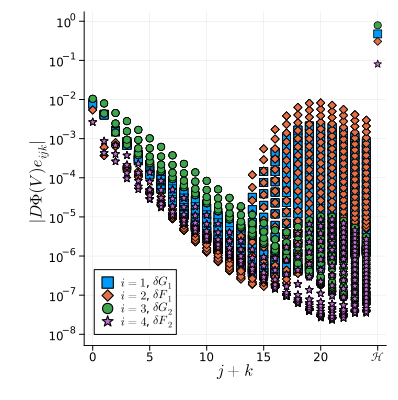

In [184]:
# here, we scatter plot norms vs homogeneous degree j+k

deg = collect(0:tri_basis_size_4-1)
ind = 1
for i=1:4
    for k=0:N #tri_basis_size_1-1 #this should be N
        for j=0:N #tri_basis_size_1-1 #this should be N
            if j+k<=N
                deg[ind] = j+k
                ind += 1
            end
        end
    end
end
println(ind)
p1 = plot(yaxis=:log10, tickdir=:out, widen=true, legend=:bottomleft, left_margin=5Plots.mm, size=halfsize)
scatter!(p1, deg, (x->x.hi).(norms_P_1), marker=:square, color=1, label=L"$i=1$, $\delta G_1$")
scatter!(p1, deg, (x->x.hi).(norms_P_2), marker=:diamond, color=2, label=L"$i=2$, $\delta F_1$")
scatter!(p1, deg, (x->x.hi).(norms_P_3), marker=:circle, color=3, label=L"$i=3$, $\delta G_2$")
scatter!(p1, deg, (x->x.hi).(norms_P_4), marker=:star5, color=4, label=L"$i=4$, $\delta F_2$")
scatter!(p1, [N+1], [high_norms[1].hi], marker=:square, color=1, label=:none)
scatter!(p1, [N+1], [high_norms[2].hi], marker=:diamond, color=2, label=:none)
scatter!(p1, [N+1], [high_norms[3].hi], marker=:circle, color=3, label=:none)
scatter!(p1, [N+1], [high_norms[4].hi], marker=:star5, color=4, label=:none)
plot!(p1, xformatter=x->(x<N ? string(Int(x)) : L"$\mathcal{H}$"))
xlabel!(p1, L"$j+k$", fontsize=12)
ylabel!(p1, L"$\| D\Phi(V)e_{ijk}\|$", fontsize=12)
yticks!([1e-8,1e-7,1e-6,1e-5,1e-4,1e-3,1e-2,1e-1,1e0])
ylims!(9e-9,1e0)
savefig(p1, "fig/C_norms.pdf")
p1

In [185]:
rmprocs(collect(2:maximum(procs()))) # cleanup

Task (done) @0x000076fdf0fa39e0